Libraries used


In [48]:
library(tidyverse) 
library(psych)     
library(car)          
library(heplots)     
library(GPArotation)  


# Data Preparation

### Data import and combining

In [49]:
red_wine <- read_delim("/kaggle/input/datasets/ivancobarrubias/wine-quality/winequality-red.csv",
                       delim = ";", locale = locale(decimal_mark = "."))
white_wine <- read_delim("/kaggle/input/datasets/ivancobarrubias/wine-quality/winequality-white.csv",
                         delim = ";", locale = locale(decimal_mark = "."))

Rows: 1599 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 4898 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [50]:
wine <- bind_rows("red" = red_wine, "white" = white_wine, .id = "color") %>%
  rename_with(~ str_replace_all(.x, " ", "_"))

vars11 <- c("fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar",
            "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide",
            "density", "pH", "sulphates", "alcohol")


# Exploratory Analysis

### Dimensions

In [51]:
glimpse(wine)
dim(wine)                 
table(wine$color)

Rows: 6,497
Columns: 13
$ color                <chr> "red", "red", "red", "red", "red", "red", "red", …
$ fixed_acidity        <dbl> 7.4, 7.8, 7.8, 11.2, 7.4, 7.4, 7.9, 7.3, 7.8, 7.5…
$ volatile_acidity     <dbl> 0.700, 0.880, 0.760, 0.280, 0.700, 0.660, 0.600, …
$ citric_acid          <dbl> 0.00, 0.00, 0.04, 0.56, 0.00, 0.00, 0.06, 0.00, 0…
$ residual_sugar       <dbl> 1.9, 2.6, 2.3, 1.9, 1.9, 1.8, 1.6, 1.2, 2.0, 6.1,…
$ chlorides            <dbl> 0.076, 0.098, 0.092, 0.075, 0.076, 0.075, 0.069, …
$ free_sulfur_dioxide  <dbl> 11, 25, 15, 17, 11, 13, 15, 15, 9, 17, 15, 17, 16…
$ total_sulfur_dioxide <dbl> 34, 67, 54, 60, 34, 40, 59, 21, 18, 102, 65, 102,…
$ density              <dbl> 0.9978, 0.9968, 0.9970, 0.9980, 0.9978, 0.9978, 0…
$ pH                   <dbl> 3.51, 3.20, 3.26, 3.16, 3.51, 3.51, 3.30, 3.39, 3…
$ sulphates            <dbl> 0.56, 0.68, 0.65, 0.58, 0.56, 0.56, 0.46, 0.47, 0…
$ alcohol              <dbl> 9.4, 9.8, 9.8, 9.8, 9.4, 9.4, 9.4, 10.0, 9.5, 10.…
$ quality       

[1] 6497   13


  red white 
 1599  4898 

### Check for NA

In [52]:
colSums(is.na(wine)) 

color        fixed_acidity     volatile_acidity 
                   0                    0                    0 
         citric_acid       residual_sugar            chlorides 
                   0                    0                    0 
 free_sulfur_dioxide total_sulfur_dioxide              density 
                   0                    0                    0 
                  pH            sulphates              alcohol 
                   0                    0                    0 
             quality 
                   0

### Check for Duplicates

In [53]:
n_dup <- sum(duplicated(wine))
n_dup
wine[duplicated(wine), ] %>% count(color)

[1] 1177

color,n
<chr>,<int>
red,240
white,937


### Check for Outliers

#### Univariate (1.5 × IQR rule, per variable):

In [54]:
iqr_out <- wine %>%
  summarise(across(all_of(vars11),
                   ~ sum(.x < quantile(.x, .25) - 1.5 * IQR(.x) |
                         .x > quantile(.x, .75) + 1.5 * IQR(.x)))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "n_outliers") %>%
  mutate(pct = round(100 * n_outliers / nrow(wine), 1))
iqr_out

variable,n_outliers,pct
<chr>,<int>,<dbl>
fixed_acidity,357,5.5
volatile_acidity,377,5.8
citric_acid,509,7.8
residual_sugar,118,1.8
chlorides,286,4.4
free_sulfur_dioxide,62,1.0
total_sulfur_dioxide,10,0.2
density,3,0.0
pH,73,1.1


#### Multivariate (Mahalanobis distance, chi-square cutoff at p < .001):

In [55]:
X_all  <- as.matrix(wine[vars11])
md_all <- mahalanobis(X_all, colMeans(X_all), cov(X_all))
cut_all <- qchisq(0.999, df = length(vars11))
sum(md_all > cut_all)
round(100 * mean(md_all > cut_all), 1)

[1] 175

[1] 2.7

#### Descriptive statistics

In [56]:
desc <- describe(wine[vars11])[, c("n", "mean", "sd", "median", "min", "max", "skew", "kurtosis")]
desc$cv <- desc$sd / desc$mean
round(desc, 3)

describeBy(wine[vars11], group = wine$color, mat = TRUE)

,n,mean,sd,median,min,max,skew,kurtosis,cv
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
fixed_acidity,6497,7.215,1.296,7.000,3.800,15.900,1.722,5.054,0.180
volatile_acidity,6497,0.340,0.165,0.290,0.080,1.580,1.494,2.820,0.485
citric_acid,6497,0.319,0.145,0.310,0.000,1.660,0.472,2.393,0.456
residual_sugar,6497,5.443,4.758,3.000,0.600,65.800,1.435,4.353,0.874
chlorides,6497,0.056,0.035,0.047,0.009,0.611,5.397,50.841,0.625
free_sulfur_dioxide,6497,30.525,17.749,29.000,1.000,289.000,1.220,7.896,0.581
total_sulfur_dioxide,6497,115.745,56.522,118.000,6.000,440.000,-0.001,-0.373,0.488
density,6497,0.995,0.003,0.995,0.987,1.039,0.503,6.597,0.003
pH,6497,3.219,0.161,3.210,2.720,4.010,0.387,0.365,0.050


,item,group1,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
fixed_acidity1,1,red,1,1599,8.31963727,1.741096318,7.90000,8.15253708,1.482600000,4.60000,15.90000,11.30000,0.98090840,1.1196987,4.354102e-02
fixed_acidity2,2,white,1,4898,6.85478767,0.843868228,6.80000,6.81656888,0.741300000,3.80000,14.20000,10.40000,0.64735478,2.1666266,1.205772e-02
volatile_acidity1,3,red,2,1599,0.52782051,0.179059704,0.52000,0.51806792,0.177912000,0.12000,1.58000,1.46000,0.67033307,1.2126893,4.477892e-03
volatile_acidity2,4,white,2,4898,0.27824112,0.100794548,0.26000,0.26747704,0.088956000,0.08000,1.10000,1.02000,1.57601374,5.0819038,1.440216e-03
citric_acid1,5,red,3,1599,0.27097561,0.194801137,0.26000,0.26128806,0.252042000,0.00000,1.00000,1.00000,0.31774029,-0.7930455,4.871551e-03
citric_acid2,6,white,3,4898,0.33419151,0.121019804,0.32000,0.32596173,0.088956000,0.00000,1.66000,1.66000,1.28113534,6.1636313,1.729207e-03
residual_sugar1,7,red,4,1599,2.53880550,1.409928060,2.20000,2.25835285,0.444780000,0.90000,15.50000,14.60000,4.53213992,28.4850200,3.525922e-02
residual_sugar2,8,white,4,4898,6.39141486,5.072057784,5.20000,5.80460459,5.337360000,0.60000,65.80000,65.20000,1.07643413,3.4624147,7.247276e-02
chlorides1,9,red,5,1599,0.08746654,0.047065302,0.07900,0.08023497,0.014826000,0.01200,0.61100,0.59900,5.66969370,41.5259635,1.177000e-03


#### Distributions

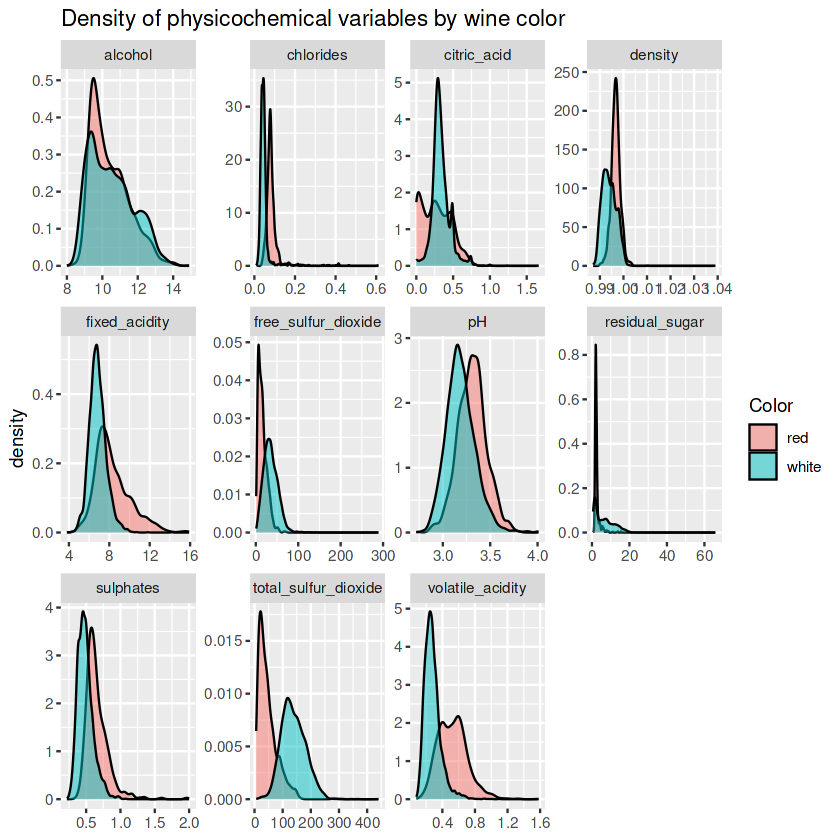

In [57]:
wine_long <- wine %>% pivot_longer(all_of(vars11), names_to = "variable", values_to = "value")

ggplot(wine_long, aes(value, fill = color)) +
  geom_density(alpha = 0.5) +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Density of physicochemical variables by wine color", x = NULL, fill = "Color")

#### Correlation Matrix

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
fixed_acidity,1.00,0.22,0.32,-0.11,0.30,-0.28,-0.33,0.46,-0.25,0.30,-0.10
volatile_acidity,0.22,1.00,-0.38,-0.20,0.38,-0.35,-0.41,0.27,0.26,0.23,-0.04
citric_acid,0.32,-0.38,1.00,0.14,0.04,0.13,0.20,0.10,-0.33,0.06,-0.01
residual_sugar,-0.11,-0.20,0.14,1.00,-0.13,0.40,0.50,0.55,-0.27,-0.19,-0.36
chlorides,0.30,0.38,0.04,-0.13,1.00,-0.20,-0.28,0.36,0.04,0.40,-0.26
free_sulfur_dioxide,-0.28,-0.35,0.13,0.40,-0.20,1.00,0.72,0.03,-0.15,-0.19,-0.18
total_sulfur_dioxide,-0.33,-0.41,0.20,0.50,-0.28,0.72,1.00,0.03,-0.24,-0.28,-0.27
density,0.46,0.27,0.10,0.55,0.36,0.03,0.03,1.00,0.01,0.26,-0.69
pH,-0.25,0.26,-0.33,-0.27,0.04,-0.15,-0.24,0.01,1.00,0.19,0.12
sulphates,0.30,0.23,0.06,-0.19,0.40,-0.19,-0.28,0.26,0.19,1.00,0.00


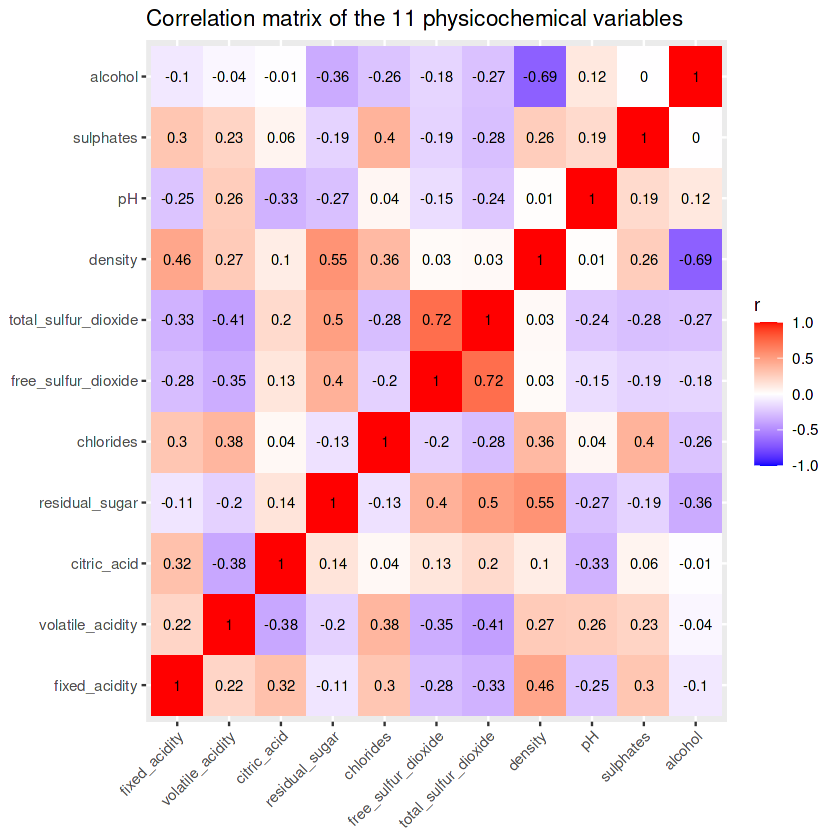

In [58]:
cor_mat <- cor(wine[vars11])
round(cor_mat, 2)

cor_long <- as.data.frame(as.table(cor_mat))
ggplot(cor_long, aes(Var1, Var2, fill = Freq)) +
  geom_tile() +
  geom_text(aes(label = round(Freq, 2)), size = 3) +
  scale_fill_gradient2(low = "blue", mid = "white", high = "red", limits = c(-1, 1)) +
  labs(title = "Correlation matrix of the 11 physicochemical variables", x = NULL, y = NULL, fill = "r") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

#### Visualizations

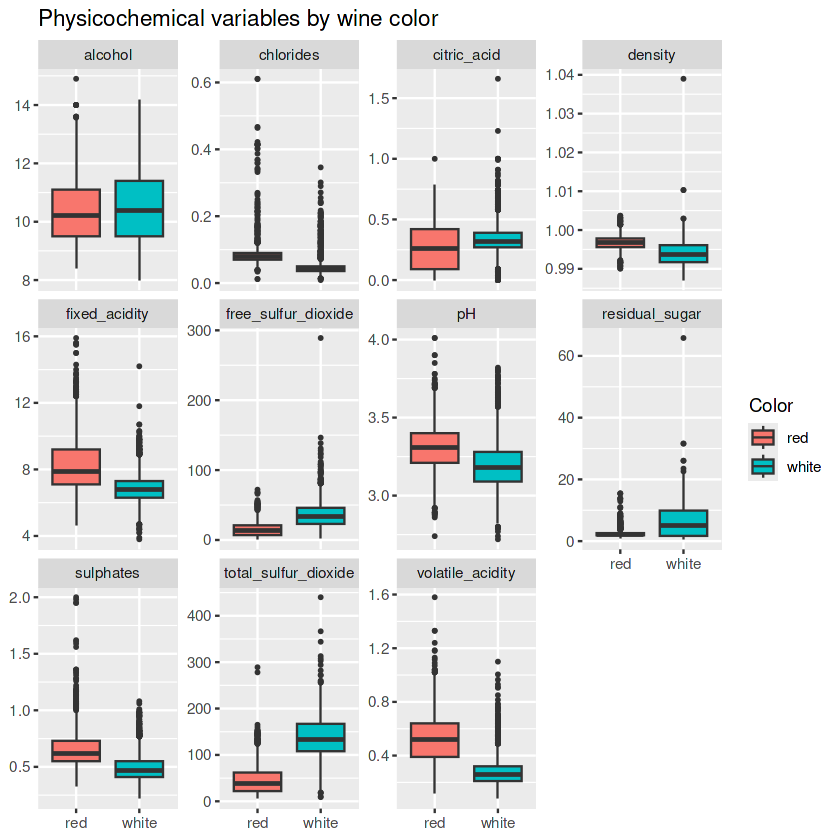

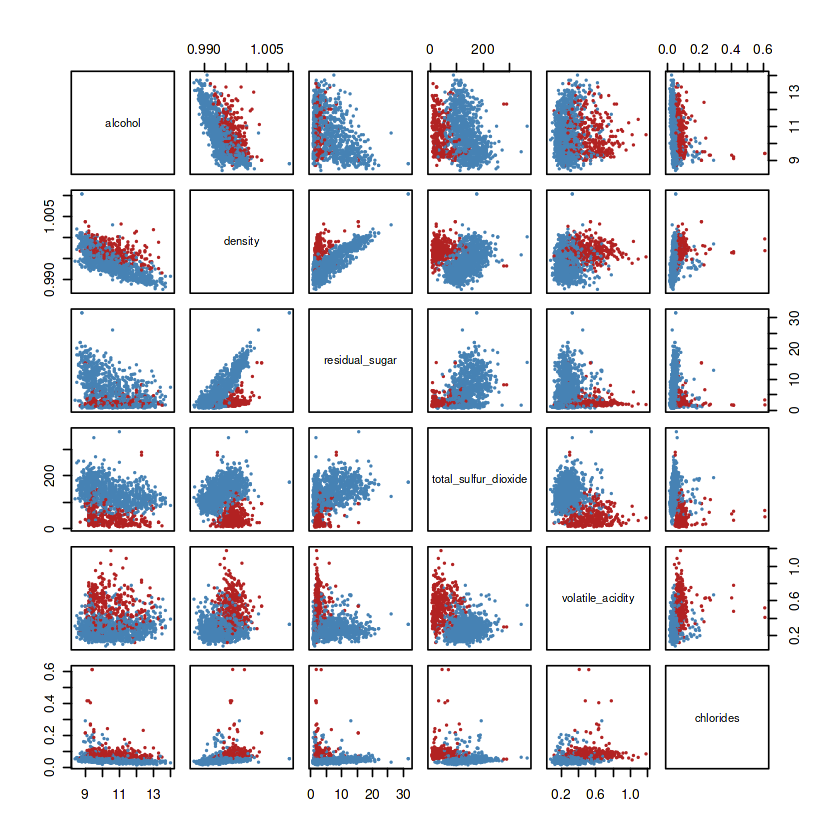

In [59]:
ggplot(wine_long, aes(color, value, fill = color)) +
  geom_boxplot(outlier.size = 0.6) +
  facet_wrap(~ variable, scales = "free_y") +
  labs(title = "Physicochemical variables by wine color", x = NULL, y = NULL, fill = "Color")

set.seed(123)
s <- sample(nrow(wine), 1500)
pairs(wine[s, c("alcohol", "density", "residual_sugar", "total_sulfur_dioxide",
                "volatile_acidity", "chlorides")],
      col = ifelse(wine$color[s] == "red", "firebrick", "steelblue"), pch = 16, cex = 0.4)

### Export

code is commented to prevent duplication of file generation during reruns of the whole notebook

In [60]:
##
#dir.create("output/figures", recursive = TRUE, showWarnings = FALSE)
#dir.create("output/tables",  recursive = TRUE, showWarnings = FALSE)

#dup_summary <- wine[duplicated(wine), ] %>% count(color)
#write_csv(dup_summary, "output/tables/duplicates_by_color.csv")

#write_csv(iqr_out, "output/tables/univariate_outliers_iqr.csv")

#write_csv(tibble(cutoff      = cut_all,
#                 n_flagged   = sum(md_all > cut_all),
#                 pct_flagged = round(100 * mean(md_all > cut_all), 1)),
#          "output/tables/multivariate_outliers.csv")

#write.csv(round(desc, 3), "output/tables/descriptives_overall.csv")
#desc_by_color <- describeBy(wine[vars11], group = wine$color, mat = TRUE)
#write.csv(desc_by_color, "output/tables/descriptives_by_color.csv")

#write.csv(round(cor_mat, 3), "output/tables/correlation_matrix.csv")

#wine_long <- wine %>% pivot_longer(all_of(vars11), names_to = "variable", values_to = "value")
#cor_long  <- as.data.frame(as.table(cor_mat))

#p_density <- ggplot(wine_long, aes(value, fill = color)) +
#  geom_density(alpha = 0.5) +
#  facet_wrap(~ variable, scales = "free") +
#  labs(title = "Density of physicochemical variables by wine color", x = NULL, fill = "Color")
#ggsave("output/figures/density_by_color.png", plot = p_density, width = 12, height = 8, dpi = 300)

#p_box <- ggplot(wine_long, aes(color, value, fill = color)) +
#  geom_boxplot(outlier.size = 0.6) +
#  facet_wrap(~ variable, scales = "free_y") +
#  labs(title = "Physicochemical variables by wine color", x = NULL, y = NULL, fill = "Color")
#ggsave("output/figures/boxplots_by_color.png", plot = p_box, width = 12, height = 8, dpi = 300)

#p_heat <- ggplot(cor_long, aes(Var1, Var2, fill = Freq)) +
#  geom_tile() +
#  geom_text(aes(label = round(Freq, 2)), size = 3) +
#  scale_fill_gradient2(low = "blue", mid = "white", high = "red", limits = c(-1, 1)) +
#  labs(title = "Correlation matrix of the 11 physicochemical variables", x = NULL, y = NULL, fill = "r") +
#  theme(axis.text.x = element_text(angle = 45, hjust = 1))
#ggsave("output/figures/correlation_heatmap.png", plot = p_heat, width = 9, height = 8, dpi = 300)

#set.seed(123)
#s <- sample(nrow(wine), 1500)
#png("output/figures/scatterplot_matrix.png", width = 2400, height = 2400, res = 300)
#pairs(wine[s, c("alcohol", "density", "residual_sugar", "total_sulfur_dioxide",
#                "volatile_acidity", "chlorides")],
#      col = ifelse(wine$color[s] == "red", "firebrick", "steelblue"), pch = 16, cex = 0.4)
#dev.off()

#list.files("output", recursive = TRUE)


# MANOVA

### Dependent Variable Selection

In [61]:
R_all <- cor(wine[vars11])
R0 <- R_all; diag(R0) <- 0
 
cohen_d <- function(v) {
  r  <- wine[[v]][wine$color == "red"];  w <- wine[[v]][wine$color == "white"]
  sp <- sqrt(((length(r) - 1) * var(r) + (length(w) - 1) * var(w)) / (length(r) + length(w) - 2))
  (mean(r) - mean(w)) / sp          # positive = higher in red
}
 
dv_evidence <- tibble(variable   = vars11,
                      mean_red   = map_dbl(vars11, ~ mean(wine[[.x]][wine$color == "red"])),
                      mean_white = map_dbl(vars11, ~ mean(wine[[.x]][wine$color == "white"])),
                      cohens_d   = map_dbl(vars11, cohen_d),
                      max_abs_r  = apply(abs(R0), 1, max),
                      most_correlated_with = vars11[apply(abs(R0), 1, which.max)],
                      VIF_all11  = diag(solve(R_all))) %>%
  arrange(desc(abs(cohens_d)))
dv_evidence %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

dvs <- c("fixed_acidity", "volatile_acidity", "residual_sugar",
         "chlorides", "total_sulfur_dioxide", "sulphates")
 
 

variable,mean_red,mean_white,cohens_d,max_abs_r,most_correlated_with,VIF_all11
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
total_sulfur_dioxide,46.468,138.361,-2.278,0.721,free_sulfur_dioxide,2.938
volatile_acidity,0.528,0.278,2.002,0.414,total_sulfur_dioxide,1.949
chlorides,0.087,0.046,1.386,0.396,sulphates,1.632
sulphates,0.658,0.490,1.295,0.396,chlorides,1.542
fixed_acidity,8.320,6.855,1.293,0.459,density,4.897
free_sulfur_dioxide,15.875,35.308,-1.242,0.721,total_sulfur_dioxide,2.135
density,0.997,0.994,0.985,0.687,alcohol,15.915
residual_sugar,2.539,6.391,-0.864,0.553,density,7.229
pH,3.311,3.188,0.809,0.330,citric_acid,2.537


In [62]:
cand7 <- c("fixed_acidity", "volatile_acidity", "residual_sugar",
           "chlorides", "total_sulfur_dioxide", "sulphates", "pH")
round(diag(solve(cor(wine[cand7]))), 2)

E7 <- residuals(manova(as.matrix(wine[cand7]) ~ factor(wine$color)))
round(diag(solve(cor(E7))), 2)      

fixed_acidity     volatile_acidity       residual_sugar 
                1.47                 1.40                 1.37 
           chlorides total_sulfur_dioxide            sulphates 
                1.37                 1.71                 1.34 
                  pH 
                1.40

fixed_acidity     volatile_acidity       residual_sugar 
                1.37                 1.06                 1.21 
           chlorides total_sulfur_dioxide            sulphates 
                1.09                 1.20                 1.10 
                  pH 
                1.42

In [63]:
dvs <- c("fixed_acidity", "volatile_acidity", "residual_sugar",
         "chlorides", "total_sulfur_dioxide", "sulphates", "pH")

mv <- wine %>% mutate(color = factor(color, levels = c("red", "white")))  
Y  <- as.matrix(mv[dvs])

table(mv$color)

group_stats <- mv %>% group_by(color) %>%
  summarise(across(all_of(dvs), list(M = mean, SD = sd), .names = "{.col}__{.fn}"))
group_stats %>% mutate(across(where(is.numeric), ~ round(.x, 3)))


  red white 
 1599  4898 

color,fixed_acidity__M,fixed_acidity__SD,volatile_acidity__M,volatile_acidity__SD,residual_sugar__M,residual_sugar__SD,chlorides__M,chlorides__SD,total_sulfur_dioxide__M,total_sulfur_dioxide__SD,sulphates__M,sulphates__SD,pH__M,pH__SD
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
red,8.320,1.741,0.528,0.179,2.539,1.410,0.087,0.047,46.468,32.895,0.658,0.170,3.311,0.154
white,6.855,0.844,0.278,0.101,6.391,5.072,0.046,0.022,138.361,42.498,0.490,0.114,3.188,0.151


### Assumption Checks

#### Independence

Independence is assessed from the study design; wines may share producers or batches, and duplicate rows cannot be verified as distinct wines.

#### Multivariate Outliers

In [64]:
mv$md <- NA_real_
for (g in levels(mv$color)) {
  idx <- mv$color == g
  Xg  <- as.matrix(mv[idx, dvs])
  mv$md[idx] <- mahalanobis(Xg, colMeans(Xg), cov(Xg))
}
cut_dv <- qchisq(0.999, df = length(dvs))
cut_dv                                  # chi-square cutoff for 7 df at p < .001 (about 24.32)

mv_out <- mv %>% group_by(color) %>%
  summarise(n = n(), n_outliers = sum(md > cut_dv), pct = round(100 * mean(md > cut_dv), 1))
mv_out

[1] 24.32189

color,n,n_outliers,pct
<fct>,<int>,<int>,<dbl>
red,1599,53,3.3
white,4898,117,2.4


#### Multivariate Normality


--- Mardia's test: red ---
Call: psych::mardia(x = as.matrix(mv[mv$color == g, dvs]), plot = FALSE)

Mardia tests of multivariate skew and kurtosis
Use describe(x) the to get univariate tests
n.obs = 1599   num.vars =  7 
b1p =  70.37   skew =  18753.69  with probability  <=  0
 small sample skew =  18797.69  with probability <=  0
b2p =  164.13   kurtosis =  180.12  with probability <=  0
--- Mardia's test: white ---
Call: psych::mardia(x = as.matrix(mv[mv$color == g, dvs]), plot = FALSE)

Mardia tests of multivariate skew and kurtosis
Use describe(x) the to get univariate tests
n.obs = 4898   num.vars =  7 
b1p =  35.34   skew =  28845.33  with probability  <=  0
 small sample skew =  28867.42  with probability <=  0
b2p =  123.16   kurtosis =  187.54  with probability <=  0

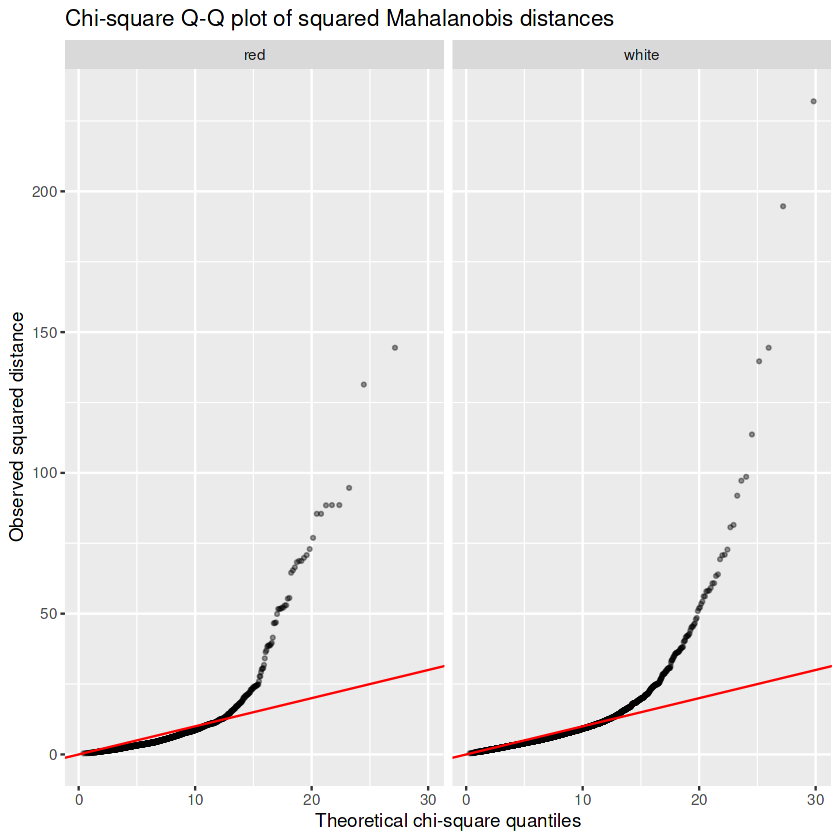

In [65]:
mardia_res <- list()
for (g in levels(mv$color)) {
  cat("\n--- Mardia's test:", g, "---\n")
  mardia_res[[g]] <- psych::mardia(as.matrix(mv[mv$color == g, dvs]), plot = FALSE)
  print(mardia_res[[g]])
}

qq <- mv %>% group_by(color) %>% arrange(md, .by_group = TRUE) %>%
  mutate(theoretical = qchisq(ppoints(n()), df = length(dvs))) %>% ungroup()

p_qq <- ggplot(qq, aes(theoretical, md)) +
  geom_point(alpha = 0.4, size = 0.7) +
  geom_abline(slope = 1, intercept = 0, color = "red") +
  facet_wrap(~ color) +
  labs(title = "Chi-square Q-Q plot of squared Mahalanobis distances",
       x = "Theoretical chi-square quantiles", y = "Observed squared distance")
p_qq

#### Homogeneity of Covariance Matrices

In [66]:
bm <- boxM(Y, mv$color)
bm

round(cov(Y[mv$color == "red", ]), 4)
round(cov(Y[mv$color == "white", ]), 4)


	Box's M-test for Homogeneity of Covariance Matrices

data:  Y
Chi-Sq (approx.) = 7533.9, df = 28, p-value < 2.2e-16


,fixed_acidity,volatile_acidity,residual_sugar,chlorides,total_sulfur_dioxide,sulphates,pH
fixed_acidity,3.0314,-0.0799,0.2818,0.0077,-6.4823,0.0540,-0.1836
volatile_acidity,-0.0799,0.0321,0.0005,0.0005,0.4504,-0.0079,0.0065
residual_sugar,0.2818,0.0005,1.9879,0.0037,9.4164,0.0013,-0.0186
chlorides,0.0077,0.0005,0.0037,0.0022,0.0734,0.0030,-0.0019
total_sulfur_dioxide,-6.4823,0.4504,9.4164,0.0734,1082.1024,0.2395,-0.3377
sulphates,0.0540,-0.0079,0.0013,0.0030,0.2395,0.0287,-0.0051
pH,-0.1836,0.0065,-0.0186,-0.0019,-0.3377,-0.0051,0.0238


,fixed_acidity,volatile_acidity,residual_sugar,chlorides,total_sulfur_dioxide,sulphates,pH
fixed_acidity,0.7121,-0.0019,0.3810,0.0004,3.2660,-0.0017,-0.0543
volatile_acidity,-0.0019,0.0102,0.0329,0.0002,0.3824,-0.0004,-0.0005
residual_sugar,0.3810,0.0329,25.7258,0.0098,86.5313,-0.0154,-0.1487
chlorides,0.0004,0.0002,0.0098,0.0005,0.1847,0.0000,-0.0003
total_sulfur_dioxide,3.2660,0.3824,86.5313,0.1847,1806.0855,0.6526,0.0149
sulphates,-0.0017,-0.0004,-0.0154,0.0000,0.6526,0.0130,0.0027
pH,-0.0543,-0.0005,-0.1487,-0.0003,0.0149,0.0027,0.0228


#### Relationships Among the Dependent Variables

In [67]:
round(cor(Y[mv$color == "red", ]), 2)  
round(cor(Y[mv$color == "white", ]), 2)

fit <- manova(Y ~ color, data = mv)       
E   <- residuals(fit)
R_E <- cor(E)                         
round(R_E, 2)

bart_dv <- cortest.bartlett(R_E, n = nrow(E))
bart_dv                                 

dv_check <- tibble(variable = dvs,
                   max_abs_r_within = apply(abs(R_E - diag(length(dvs))), 1, max),
                   VIF_within = diag(solve(R_E)))
dv_check %>% mutate(across(where(is.numeric), ~ round(.x, 2)))   
det(R_E)                                 

,fixed_acidity,volatile_acidity,residual_sugar,chlorides,total_sulfur_dioxide,sulphates,pH
fixed_acidity,1.00,-0.26,0.11,0.09,-0.11,0.18,-0.68
volatile_acidity,-0.26,1.00,0.00,0.06,0.08,-0.26,0.23
residual_sugar,0.11,0.00,1.00,0.06,0.20,0.01,-0.09
chlorides,0.09,0.06,0.06,1.00,0.05,0.37,-0.27
total_sulfur_dioxide,-0.11,0.08,0.20,0.05,1.00,0.04,-0.07
sulphates,0.18,-0.26,0.01,0.37,0.04,1.00,-0.20
pH,-0.68,0.23,-0.09,-0.27,-0.07,-0.20,1.00


,fixed_acidity,volatile_acidity,residual_sugar,chlorides,total_sulfur_dioxide,sulphates,pH
fixed_acidity,1.00,-0.02,0.09,0.02,0.09,-0.02,-0.43
volatile_acidity,-0.02,1.00,0.06,0.07,0.09,-0.04,-0.03
residual_sugar,0.09,0.06,1.00,0.09,0.40,-0.03,-0.19
chlorides,0.02,0.07,0.09,1.00,0.20,0.02,-0.09
total_sulfur_dioxide,0.09,0.09,0.40,0.20,1.00,0.13,0.00
sulphates,-0.02,-0.04,-0.03,0.02,0.13,1.00,0.16
pH,-0.43,-0.03,-0.19,-0.09,0.00,0.16,1.00


,fixed_acidity,volatile_acidity,residual_sugar,chlorides,total_sulfur_dioxide,sulphates,pH
fixed_acidity,1.00,-0.15,0.07,0.06,0.02,0.08,-0.50
volatile_acidity,-0.15,1.00,0.04,0.07,0.08,-0.14,0.07
residual_sugar,0.07,0.04,1.00,0.06,0.38,-0.02,-0.17
chlorides,0.06,0.07,0.06,1.00,0.13,0.19,-0.15
total_sulfur_dioxide,0.02,0.08,0.38,0.13,1.00,0.11,-0.01
sulphates,0.08,-0.14,-0.02,0.19,0.11,1.00,0.04
pH,-0.50,0.07,-0.17,-0.15,-0.01,0.04,1.00


$chisq
[1] 4168.796

$p.value
[1] 0

$df
[1] 21

variable,max_abs_r_within,VIF_within
<chr>,<dbl>,<dbl>
fixed_acidity,0.50,1.37
volatile_acidity,0.15,1.06
residual_sugar,0.38,1.21
chlorides,0.19,1.09
total_sulfur_dioxide,0.38,1.20
sulphates,0.19,1.10
pH,0.50,1.42


[1] 0.5262068

### Multivariate Test

In [68]:
tests <- c("Pillai", "Wilks", "Hotelling-Lawley", "Roy")
manova_tab <- map_dfr(tests, function(t) {
  s <- summary(fit, test = t)$stats["color", ]
  tibble(test = t, statistic = unname(s[2]), F = unname(s[3]),
         df1 = unname(s[4]), df2 = unname(s[5]), p = unname(s[6]))
})
manova_tab

wilks <- summary(fit, test = "Wilks")$stats["color", "Wilks"]
eta2_multivariate <- 1 - wilks   
eta2_multivariate

test,statistic,F,df1,df2,p
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Pillai,0.7914838,3518.698,7,6489,0
Wilks,0.2085162,3518.698,7,6489,0
Hotelling-Lawley,3.7957908,3518.698,7,6489,0
Roy,3.7957908,3518.698,7,6489,0


[1] 0.7914838

### Followup Analyses

variable,F,df1,df2,p,p_bonferroni,p_welch,eta2,cohens_d
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
total_sulfur_dioxide,6253.0,1,6495,0.000e+00,0.000e+00,0.000e+00,0.4905,-2.2780
volatile_acidity,4829.0,1,6495,0.000e+00,0.000e+00,0.000e+00,0.4265,2.0020
chlorides,2316.0,1,6495,0.000e+00,0.000e+00,6.095e-199,0.2628,1.3860
sulphates,2022.0,1,6495,0.000e+00,0.000e+00,1.679e-231,0.2374,1.2950
fixed_acidity,2017.0,1,6495,0.000e+00,0.000e+00,5.668e-183,0.2369,1.2930
residual_sugar,899.8,1,6495,2.959e-185,2.072e-184,0.000e+00,0.1217,-0.8639
pH,789.0,1,6495,5.923e-164,4.146e-163,2.342e-149,0.1083,0.8090


Bonferroni-adjusted alpha = 0.0071 


variable,std_coef,structure_r
<chr>,<dbl>,<dbl>
total_sulfur_dioxide,0.648,0.787
volatile_acidity,-0.568,-0.734
fixed_acidity,-0.566,-0.547
pH,-0.465,-0.370
chlorides,-0.325,-0.576
sulphates,-0.307,-0.548
residual_sugar,-0.053,0.392


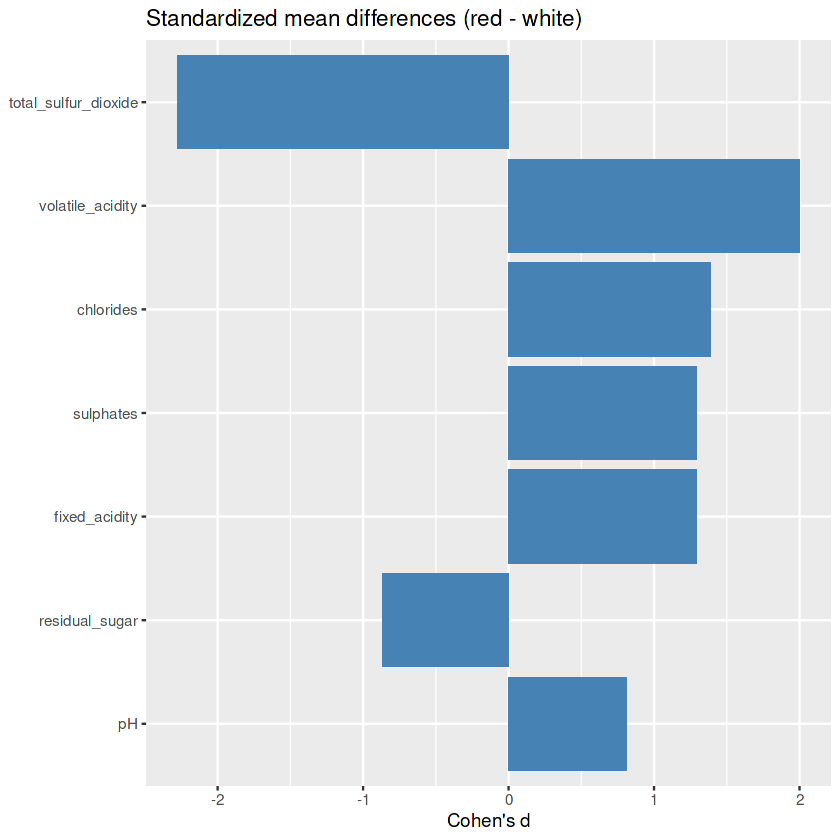

In [69]:
m <- length(dvs)

follow_up <- map_dfr(dvs, function(v) {
  a  <- summary(aov(mv[[v]] ~ mv$color))[[1]]
  ss <- a[["Sum Sq"]]
  r  <- mv[[v]][mv$color == "red"]
  w  <- mv[[v]][mv$color == "white"]
  sp <- sqrt(((length(r) - 1) * var(r) + (length(w) - 1) * var(w)) / (length(r) + length(w) - 2))
  tibble(variable = v,
         F = a[["F value"]][1], df1 = a[["Df"]][1], df2 = a[["Df"]][2],
         p = a[["Pr(>F)"]][1],
         p_bonferroni = min(a[["Pr(>F)"]][1] * m, 1),
         p_welch = t.test(mv[[v]] ~ mv$color)$p.value,     
         eta2 = ss[1] / sum(ss),
         cohens_d = (mean(r) - mean(w)) / sp)            
}) %>% arrange(desc(eta2))

follow_up %>% mutate(across(where(is.numeric), ~ signif(.x, 4)))
cat("Bonferroni-adjusted alpha =", round(0.05 / m, 4), "\n")

S_pooled <- Reduce(`+`, lapply(levels(mv$color), function(g) {
  x <- Y[mv$color == g, ]; (nrow(x) - 1) * cov(x) })) / (nrow(Y) - 2)
lda_fit <- MASS::lda(Y, grouping = mv$color)
disc <- tibble(variable    = dvs,
               std_coef    = as.numeric(lda_fit$scaling[, 1]) * sqrt(diag(S_pooled)),
               structure_r = as.numeric(cor(Y, predict(lda_fit)$x[, 1])))
disc %>% mutate(across(where(is.numeric), ~ round(.x, 3))) %>% arrange(desc(abs(std_coef)))

p_d <- ggplot(follow_up, aes(reorder(variable, abs(cohens_d)), cohens_d)) +
  geom_col(fill = "steelblue") + coord_flip() +
  labs(title = "Standardized mean differences (red - white)", x = NULL, y = "Cohen's d")
p_d

### Export

In [70]:
# ---- Export MANOVA tables and figures ----
#dir.create("output/figures", recursive = TRUE, showWarnings = FALSE)
#dir.create("output/tables",  recursive = TRUE, showWarnings = FALSE)

# Tables
#write_csv(dv_evidence, "output/tables/manova_dv_selection_evidence.csv")
#write_csv(group_stats, "output/tables/manova_group_means_sds.csv")
#write_csv(mv_out,      "output/tables/manova_multivariate_outliers.csv")
#write_csv(dv_check,    "output/tables/manova_dv_redundancy_check.csv")
#write_csv(manova_tab,  "output/tables/manova_tests.csv")
#write_csv(follow_up,   "output/tables/manova_followup_anova.csv")
#write_csv(disc,        "output/tables/manova_discriminant_coefficients.csv")
#write_csv(tibble(eta2_partial = eta2_multivariate), "output/tables/manova_effect_size.csv")
#write_csv(tibble(box_M = unname(bm$statistic), df = unname(bm$parameter), p = bm$p.value),
#          "output/tables/manova_boxM.csv")
#write_csv(tibble(bartlett_chisq = bart_dv$chisq, df = bart_dv$df, p = bart_dv$p.value),
#          "output/tables/manova_dv_bartlett.csv")
#write_csv(map_dfr(names(mardia_res), function(g) {
#  mr <- mardia_res[[g]]
#  tibble(color = g, n = mr$n.obs, skewness = mr$b1p, skew_chisq = mr$skew, p_skew = mr$p.skew,
#         kurtosis = mr$b2p, kurt_z = mr$kurtosis, p_kurt = mr$p.kurt)
#}), "output/tables/manova_mardia.csv")
#write.csv(round(R_E, 3),                           "output/tables/manova_dv_correlations_residual.csv")
#write.csv(round(cor(Y[mv$color == "red", ]), 3),   "output/tables/manova_dv_correlations_red.csv")
#write.csv(round(cor(Y[mv$color == "white", ]), 3), "output/tables/manova_dv_correlations_white.csv")
#write.csv(round(cov(Y[mv$color == "red", ]), 5),   "output/tables/manova_covariance_red.csv")
#write.csv(round(cov(Y[mv$color == "white", ]), 5), "output/tables/manova_covariance_white.csv")

# Figures
#ggsave("output/figures/manova_qq_plot.png",  plot = p_qq, width = 9, height = 4.5, dpi = 300)
#ggsave("output/figures/manova_cohens_d.png", plot = p_d,  width = 7, height = 4,   dpi = 300)
#
#list.files("output", recursive = TRUE)
#write_csv(tibble(chisq_cutoff_7df   = cut_dv,
#                 det_residual_corr  = det(R_E),
#                 max_VIF_within     = max(dv_check$VIF_within),
#                 max_abs_r_within   = max(dv_check$max_abs_r_within)),
#          "output/tables/manova_other_statistics.csv")

# PCA

### Correlation Structure

In [71]:
R11   <- cor(wine[vars11])
r_low <- R11[lower.tri(R11)]

pair_counts <- tibble(total_pairs = length(r_low),
                      abs_r_ge_30 = sum(abs(r_low) >= .30),
                      abs_r_ge_50 = sum(abs(r_low) >= .50),
                      max_abs_r   = max(abs(r_low)))
pair_counts

kmo11 <- KMO(R11)
round(kmo11$MSA, 3)     
round(kmo11$MSAi, 2)   

bart11 <- cortest.bartlett(R11, n = nrow(wine))
bart11                  

total_pairs,abs_r_ge_30,abs_r_ge_50,max_abs_r
<int>,<int>,<int>,<dbl>
55,16,3,0.7209341


[1] 0.405

fixed_acidity     volatile_acidity          citric_acid 
                0.28                 0.61                 0.62 
      residual_sugar            chlorides  free_sulfur_dioxide 
                0.29                 0.73                 0.75 
total_sulfur_dioxide              density                   pH 
                0.72                 0.30                 0.21 
           sulphates              alcohol 
                0.56                 0.27

$chisq
[1] 37094.62

$p.value
[1] 0

$df
[1] 55

### Standardization and PCA

In [72]:
pca <- prcomp(wine[vars11], center = TRUE, scale. = TRUE)

all.equal(unname(eigen(R11)$values), unname(pca$sdev^2))

eig <- pca$sdev^2
var_tbl <- tibble(PC         = paste0("PC", seq_along(eig)),
                  eigenvalue = eig,
                  prop_var   = eig / sum(eig),
                  cum_prop   = cumsum(eig / sum(eig)))
var_tbl %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

[1] TRUE

PC,eigenvalue,prop_var,cum_prop
<chr>,<dbl>,<dbl>,<dbl>
PC1,3.030,0.275,0.275
PC2,2.494,0.227,0.502
PC3,1.556,0.141,0.644
PC4,0.971,0.088,0.732
PC5,0.720,0.065,0.797
PC6,0.607,0.055,0.853
PC7,0.523,0.048,0.900
PC8,0.502,0.046,0.946
PC9,0.337,0.031,0.976


### Component Retention: Parallel Analysis

Parallel analysis suggests that the number of factors =  NA  and the number of components =  3 


[1] 3

PC,eigenvalue,prop_var,cum_prop,pa_threshold,kaiser_gt1,exceeds_pa
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>
PC1,3.030,0.275,0.275,1.064,TRUE,TRUE
PC2,2.494,0.227,0.502,1.048,TRUE,TRUE
PC3,1.556,0.141,0.644,1.034,TRUE,TRUE
PC4,0.971,0.088,0.732,1.021,FALSE,FALSE
PC5,0.720,0.065,0.797,1.011,FALSE,FALSE
PC6,0.607,0.055,0.853,0.999,FALSE,FALSE
PC7,0.523,0.048,0.900,0.989,FALSE,FALSE
PC8,0.502,0.046,0.946,0.978,FALSE,FALSE
PC9,0.337,0.031,0.976,0.966,FALSE,FALSE


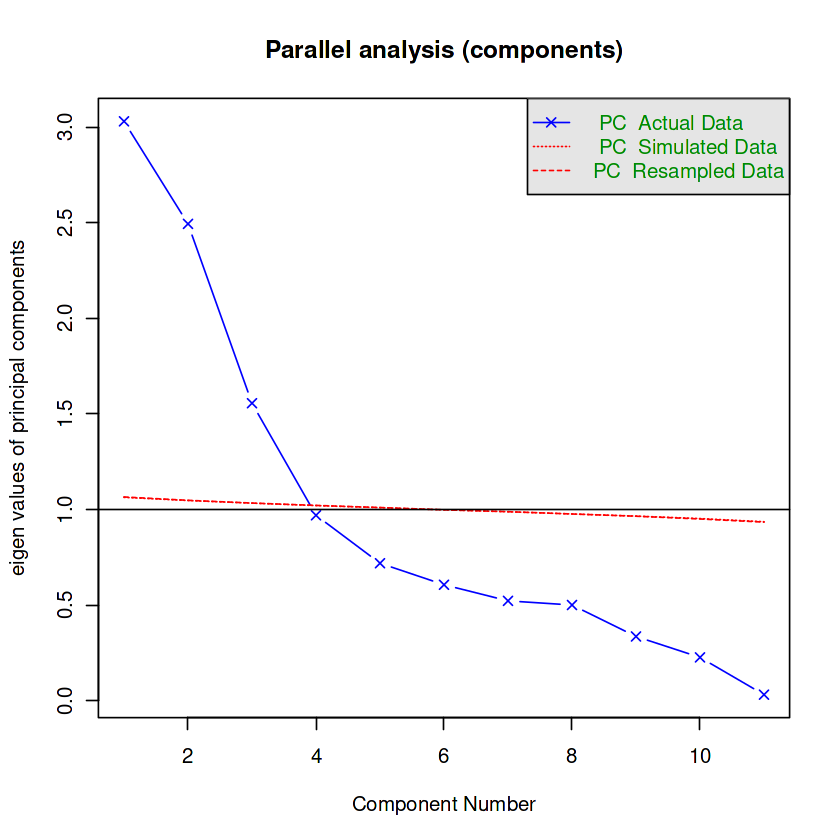

In [73]:
set.seed(123)
pa <- fa.parallel(wine[vars11], fa = "pc", n.iter = 100, quant = .95,
                  main = "Parallel analysis (components)")

# with quant = .95, pa$pc.sim is the 95th percentile of the random-data eigenvalues
pa$ncomp    # number of components suggested by parallel analysis

retention_tbl <- var_tbl %>%
  mutate(pa_threshold = pa$pc.sim[seq_along(eig)],
         kaiser_gt1   = eigenvalue > 1,
         exceeds_pa   = eigenvalue > pa_threshold)
retention_tbl %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

### Scree Plot

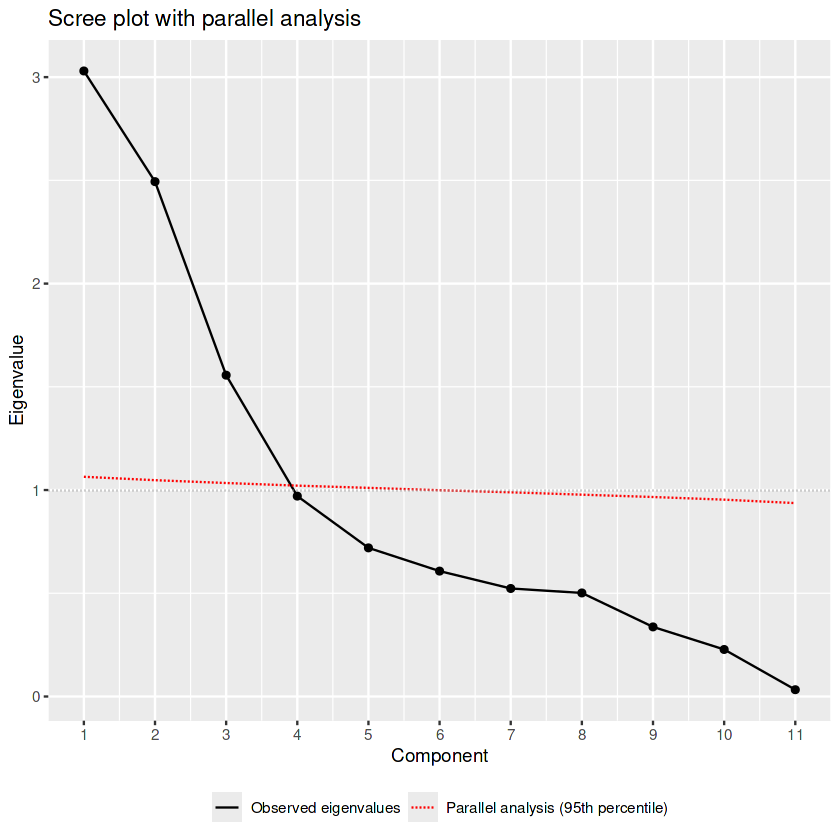

In [74]:
p_scree <- retention_tbl %>%
  mutate(idx = row_number()) %>%
  ggplot(aes(idx)) +
  geom_line(aes(y = eigenvalue, linetype = "Observed eigenvalues")) +
  geom_point(aes(y = eigenvalue)) +
  geom_line(aes(y = pa_threshold, linetype = "Parallel analysis (95th percentile)"),
            color = "red") +
  geom_hline(yintercept = 1, color = "grey60", linetype = "dotted") +
  scale_x_continuous(breaks = 1:11) +
  labs(title = "Scree plot with parallel analysis",
       x = "Component", y = "Eigenvalue", linetype = NULL) +
  theme(legend.position = "bottom")
p_scree

### Component Loadings

In [75]:
k <- 3   

eigvec <- pca$rotation[, 1:k, drop = FALSE]
load_k <- sweep(eigvec, 2, pca$sdev[1:k], "*")    

flip   <- apply(load_k, 2, function(x) sign(x[which.max(abs(x))]))
load_k <- sweep(load_k, 2, flip, "*")
colnames(load_k) <- paste0("PC", 1:k)

contrib <- 100 * eigvec^2                          
colnames(contrib) <- paste0("PC", 1:k)

loadings_tbl <- as_tibble(load_k, rownames = "variable") %>%
  mutate(communality = rowSums(load_k^2))

round_df <- function(d, n = 2) d %>% mutate(across(where(is.numeric), ~ round(.x, n)))

round_df(loadings_tbl)                                 
round_df(as_tibble(contrib, rownames = "variable"), 1)  

for (j in 1:k) {
  cat("\nPC", j, "- |loading| >= .40:\n", sep = "")
  v <- load_k[abs(load_k[, j]) >= .40, j]
  print(round(sort(v, decreasing = TRUE), 2))
}

variable,PC1,PC2,PC3,communality
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
fixed_acidity,-0.42,0.53,0.54,0.75
volatile_acidity,-0.66,0.19,-0.38,0.62
citric_acid,0.27,0.29,0.74,0.70
residual_sugar,0.60,0.52,-0.21,0.68
chlorides,-0.50,0.50,-0.02,0.50
free_sulfur_dioxide,0.75,0.11,-0.17,0.60
total_sulfur_dioxide,0.85,0.14,-0.13,0.76
density,-0.08,0.92,-0.22,0.90
pH,-0.38,-0.25,-0.57,0.53


variable,PC1,PC2,PC3
<chr>,<dbl>,<dbl>,<dbl>
fixed_acidity,5.7,11.3,18.9
volatile_acidity,14.5,1.4,9.4
citric_acid,2.3,3.4,34.9
residual_sugar,12.0,10.9,2.7
chlorides,8.4,9.9,0.0
free_sulfur_dioxide,18.6,0.5,1.8
total_sulfur_dioxide,23.8,0.8,1.2
density,0.2,34.1,3.1
pH,4.8,2.4,20.7



PC1- |loading| >= .40:
total_sulfur_dioxide  free_sulfur_dioxide       residual_sugar 
                0.85                 0.75                 0.60 
       fixed_acidity            chlorides            sulphates 
               -0.42                -0.50                -0.51 
    volatile_acidity 
               -0.66 

PC2- |loading| >= .40:
       density  fixed_acidity residual_sugar      chlorides        alcohol 
          0.92           0.53           0.52           0.50          -0.73 

PC3- |loading| >= .40:
  citric_acid fixed_acidity            pH 
         0.74          0.54         -0.57 


### Loading Plots and Biplots

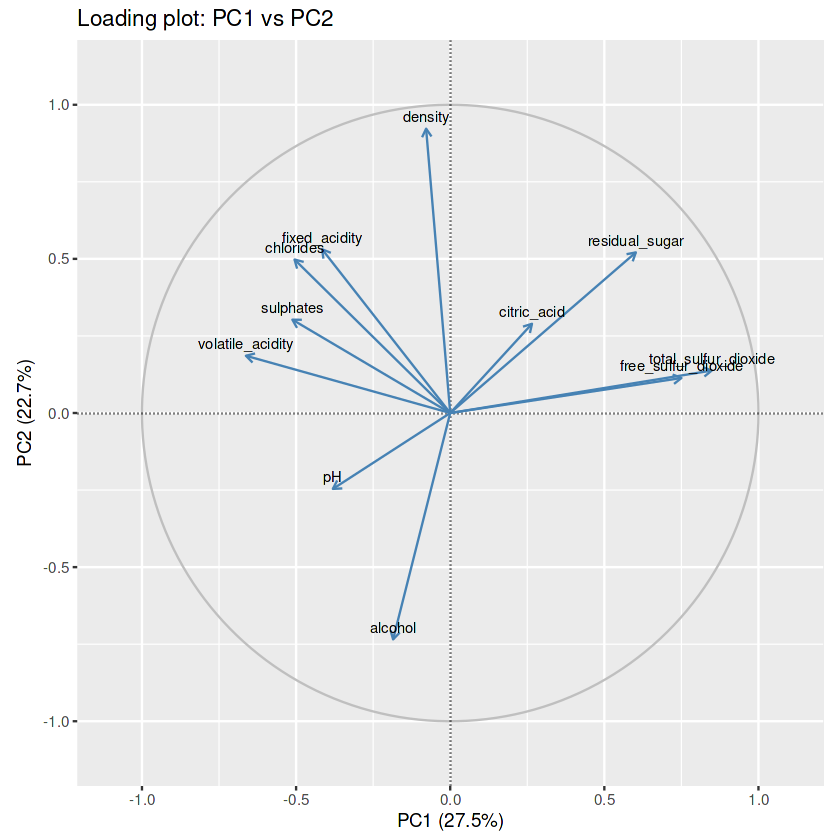

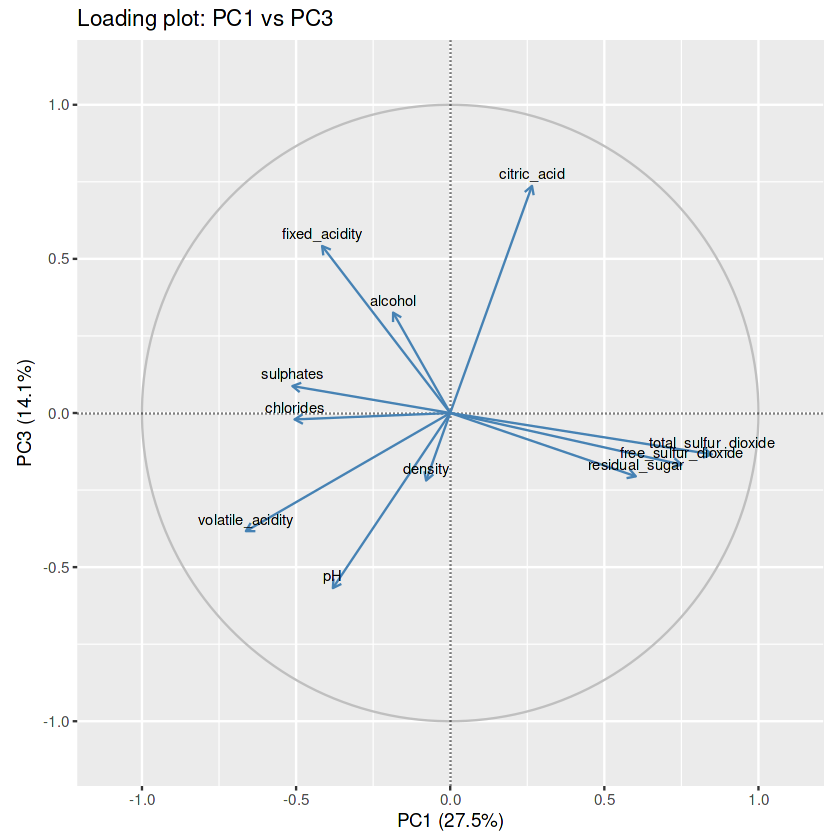

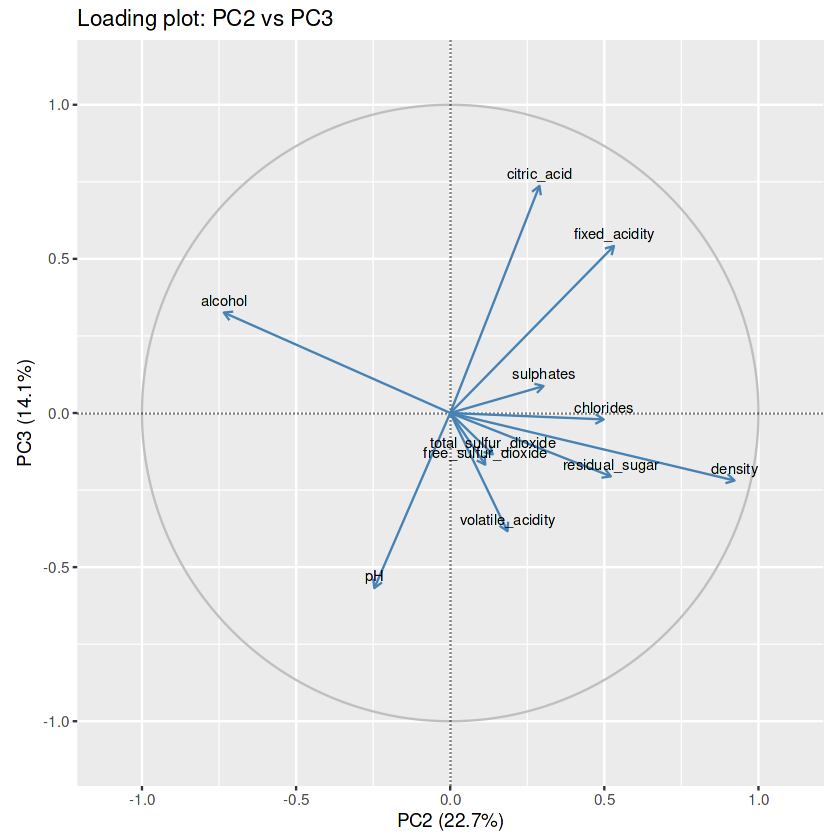

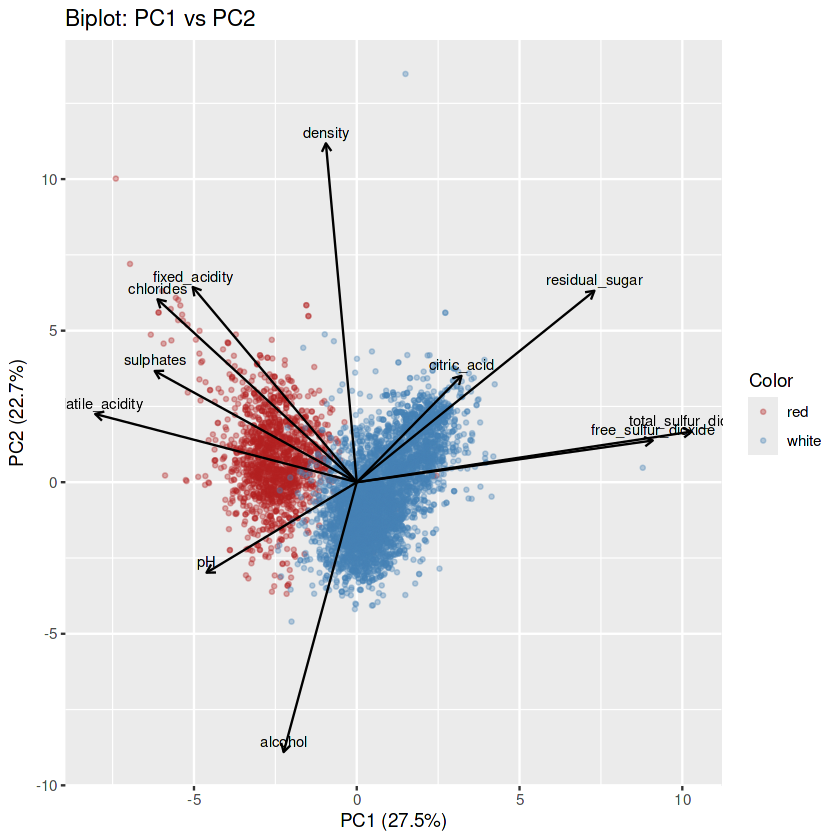

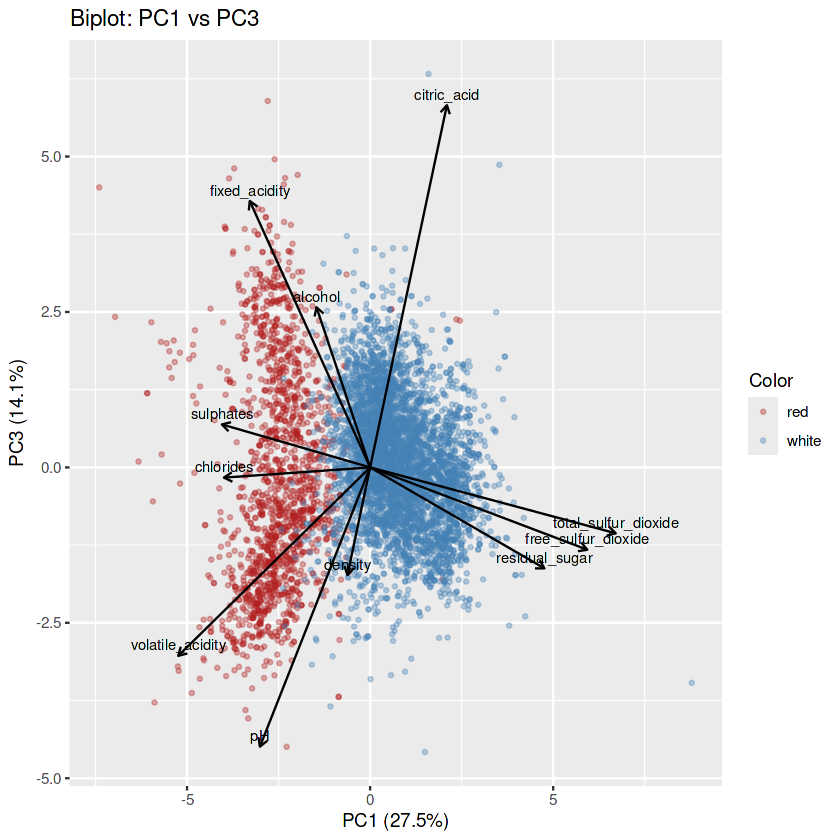

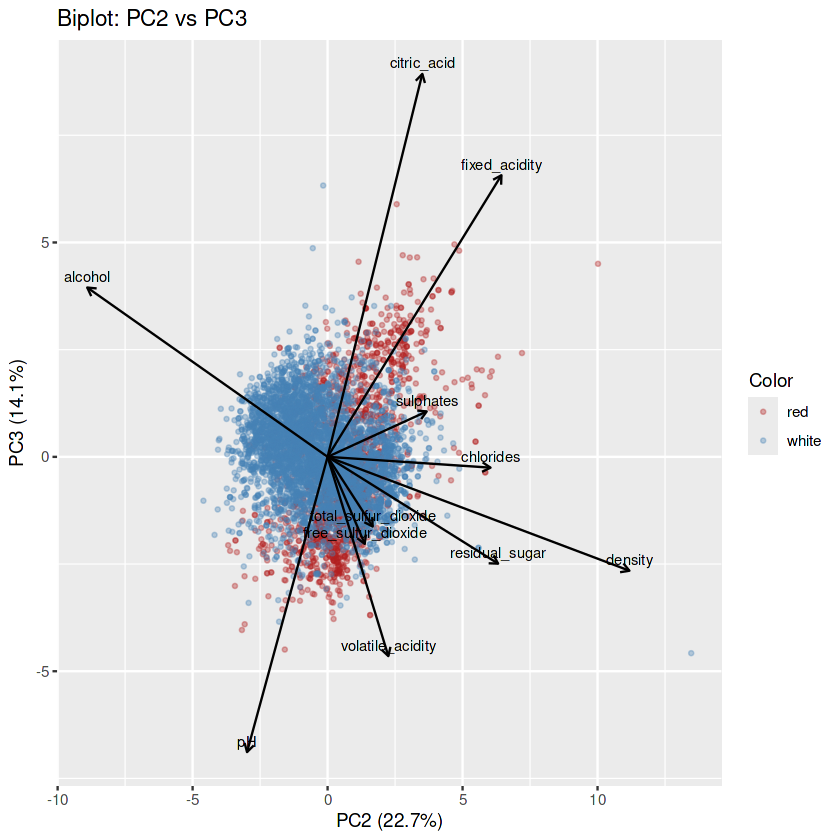

In [76]:
load_df <- as.data.frame(load_k) %>% rownames_to_column("variable")
scores  <- sweep(pca$x[, 1:k, drop = FALSE], 2, flip, "*")    # same sign convention as loadings
colnames(scores) <- paste0("PC", 1:k)
score_df <- bind_cols(as_tibble(scores), color = wine$color)
axis_lab <- function(j) sprintf("PC%d (%.1f%%)", j, 100 * var_tbl$prop_var[j])

loading_plot <- function(a, b) {
  xa <- paste0("PC", a); xb <- paste0("PC", b)
  circle <- tibble(t = seq(0, 2 * pi, length.out = 200), x = cos(t), y = sin(t))
  ggplot(load_df) +
    geom_path(data = circle, aes(x, y), color = "grey75") +
    geom_hline(yintercept = 0, linetype = "dotted") +
    geom_vline(xintercept = 0, linetype = "dotted") +
    geom_segment(aes(x = 0, y = 0, xend = .data[[xa]], yend = .data[[xb]]),
                 arrow = arrow(length = unit(0.2, "cm")), color = "steelblue") +
    geom_text(aes(.data[[xa]], .data[[xb]], label = variable), vjust = -0.6, size = 3) +
    coord_fixed(xlim = c(-1.1, 1.1), ylim = c(-1.1, 1.1)) +
    labs(title = paste("Loading plot:", xa, "vs", xb), x = axis_lab(a), y = axis_lab(b))
}

biplot_pc <- function(a, b) {
  xa <- paste0("PC", a); xb <- paste0("PC", b)
  s  <- 0.9 * max(abs(score_df[c(xa, xb)]))        # stretch arrows to the score scale
  ggplot() +
    geom_point(data = score_df, aes(.data[[xa]], .data[[xb]], color = color),
               alpha = 0.35, size = 0.8) +
    geom_segment(data = load_df,
                 aes(x = 0, y = 0, xend = s * .data[[xa]], yend = s * .data[[xb]]),
                 arrow = arrow(length = unit(0.2, "cm")), color = "black") +
    geom_text(data = load_df,
              aes(s * .data[[xa]], s * .data[[xb]], label = variable),
              size = 3, vjust = -0.5) +
    scale_color_manual(values = c(red = "firebrick", white = "steelblue")) +
    labs(title = paste("Biplot:", xa, "vs", xb), x = axis_lab(a), y = axis_lab(b), color = "Color")
}

pc_pairs   <- combn(k, 2, simplify = FALSE)          # (1,2), (1,3), (2,3)
p_loadings <- lapply(pc_pairs, function(p) loading_plot(p[1], p[2]))
p_biplots  <- lapply(pc_pairs, function(p) biplot_pc(p[1], p[2]))
for (p in p_loadings) print(p)
for (p in p_biplots)  print(p)

### Do the Components Separate Red from White Wines?

In [77]:
score_by_color <- score_df %>%
  pivot_longer(starts_with("PC"), names_to = "PC", values_to = "score") %>%
  group_by(PC, color) %>%
  summarise(M = mean(score), SD = sd(score), .groups = "drop")
round_df(score_by_color)

score_d <- sapply(1:k, function(j) {
  x <- score_df[[paste0("PC", j)]]; g <- score_df$color
  sp <- sqrt(((sum(g == "red") - 1) * var(x[g == "red"]) +
              (sum(g == "white") - 1) * var(x[g == "white"])) / (length(x) - 2))
  (mean(x[g == "red"]) - mean(x[g == "white"])) / sp
})
names(score_d) <- paste0("PC", 1:k)
round(score_d, 2)

PC,color,M,SD
<chr>,<chr>,<dbl>,<dbl>
PC1,red,-2.51,0.89
PC1,white,0.82,1.01
PC2,red,0.78,1.43
PC2,white,-0.25,1.54
PC3,red,-0.18,1.77
PC3,white,0.06,1.02


PC1   PC2   PC3 
-3.39  0.68 -0.20

### Sensitivity Check: PCA Without Multivariate Outliers

In [78]:
keep    <- md_all <= cut_all
sum(!keep)                                      

pca_out  <- prcomp(wine[keep, vars11], center = TRUE, scale. = TRUE)
load_out <- sweep(pca_out$rotation[, 1:k, drop = FALSE], 2, pca_out$sdev[1:k], "*")

var_compare <- tibble(PC           = paste0("PC", 1:k),
                      prop_with    = var_tbl$prop_var[1:k],
                      prop_without = (pca_out$sdev^2 / sum(pca_out$sdev^2))[1:k])
var_compare %>% mutate(across(where(is.numeric), ~ round(.x, 3)))
round(cumsum(var_compare$prop_with)[k], 3)
round(cumsum(var_compare$prop_without)[k], 3)


round(abs(diag(factor.congruence(load_k, load_out))), 3)

[1] 175

PC,prop_with,prop_without
<chr>,<dbl>,<dbl>
PC1,0.275,0.292
PC2,0.227,0.231
PC3,0.141,0.143


[1] 0.644

[1] 0.666

PC1  PC2  PC3 
1.00 0.99 0.99

### Export

In [80]:
# ---- Export PCA tables and figures ----
#dir.create("output/figures", recursive = TRUE, showWarnings = FALSE)
#dir.create("output/tables",  recursive = TRUE, showWarnings = FALSE)

# Tables
#write_csv(pair_counts, "output/tables/pca_correlation_pair_counts.csv")
#write_csv(tibble(variable = vars11, MSA = as.numeric(kmo11$MSAi)),
#          "output/tables/pca_kmo_by_variable.csv")
#write_csv(tibble(kmo_overall = as.numeric(kmo11$MSA), bartlett_chisq = bart11$chisq,
#                 df = bart11$df, p = bart11$p.value),
#          "output/tables/pca_kmo_bartlett.csv")
#write_csv(retention_tbl, "output/tables/pca_eigenvalues_retention.csv")
#write_csv(loadings_tbl,  "output/tables/pca_loadings_communalities.csv")
#write_csv(as_tibble(contrib, rownames = "variable"), "output/tables/pca_contributions.csv")
#write_csv(score_by_color, "output/tables/pca_scores_by_color.csv")
#write_csv(tibble(PC = names(score_d), cohens_d_red_minus_white = as.numeric(score_d)),
#          "output/tables/pca_scores_cohens_d.csv")
#write_csv(var_compare, "output/tables/pca_sensitivity_variance.csv")
#write_csv(tibble(PC = paste0("PC", 1:k),
#                 congruence = as.numeric(abs(diag(factor.congruence(load_k, load_out))))),
#          "output/tables/pca_sensitivity_congruence.csv")

# Figures
#ggsave("output/figures/pca_scree_parallel.png", plot = p_scree, width = 7, height = 4.5, dpi = 300)
#for (i in seq_along(pc_pairs)) {
#  nm <- paste0("pc", pc_pairs[[i]][1], "_pc", pc_pairs[[i]][2])
#  ggsave(sprintf("output/figures/pca_loadings_%s.png", nm), plot = p_loadings[[i]],
#         width = 6, height = 6, dpi = 300)
#  ggsave(sprintf("output/figures/pca_biplot_%s.png", nm), plot = p_biplots[[i]],
#         width = 8, height = 6, dpi = 300)
#}

#list.files("output", recursive = TRUE)

[1] "figures/manova_cohens_d.png"                
 [2] "figures/manova_qq_plot.png"                 
 [3] "figures/pca_biplot_pc1_pc2.png"             
 [4] "figures/pca_biplot_pc1_pc3.png"             
 [5] "figures/pca_biplot_pc2_pc3.png"             
 [6] "figures/pca_loadings_pc1_pc2.png"           
 [7] "figures/pca_loadings_pc1_pc3.png"           
 [8] "figures/pca_loadings_pc2_pc3.png"           
 [9] "figures/pca_scree_parallel.png"             
[10] "tables/manova_boxM.csv"                     
[11] "tables/manova_covariance_red.csv"           
[12] "tables/manova_covariance_white.csv"         
[13] "tables/manova_discriminant_coefficients.csv"
[14] "tables/manova_dv_bartlett.csv"              
[15] "tables/manova_dv_correlations_red.csv"      
[16] "tables/manova_dv_correlations_residual.csv" 
[17] "tables/manova_dv_correlations_white.csv"    
[18] "tables/manova_dv_redundancy_check.csv"      
[19] "tables/manova_dv_selection_evidence.csv"    
[20] "tables/manova_effect_size.csv"              
[21] "tables/manova_followup_anova.csv"           
[22] "tables/manova_group_means_sds.csv"          
[23] "tables/manova_mardia.csv"                   
[24] "tables/manova_multivariate_outliers.csv"    
[25] "tables/manova_other_statistics.csv"         
[26] "tables/manova_tests.csv"                    
[27] "tables/pca_contributions.csv"               
[28] "tables/pca_correlation_pair_counts.csv"     
[29] "tables/pca_eigenvalues_retention.csv"       
[30] "tables/pca_kmo_bartlett.csv"                
[31] "tables/pca_kmo_by_variable.csv"             
[32] "tables/pca_loadings_communalities.csv"      
[33] "tables/pca_scores_by_color.csv"             
[34] "tables/pca_scores_cohens_d.csv"             
[35] "tables/pca_sensitivity_congruence.csv"      
[36] "tables/pca_sensitivity_variance.csv"

# EFA

### Factorability

In [81]:
R11 <- cor(wine[vars11])
 
kmo_efa <- KMO(R11)
round(kmo_efa$MSA, 3)               
round(kmo_efa$MSAi, 2)             
 
bart_efa <- cortest.bartlett(R11, n = nrow(wine))
bart_efa                            
det(R11)                            

kmo_red   <- KMO(cor(wine[wine$color == "red",   vars11]))
kmo_white <- KMO(cor(wine[wine$color == "white", vars11]))
vars_nodens <- setdiff(vars11, "density")
kmo_nodens  <- KMO(cor(wine[vars_nodens]))
 
tibble(analysis = c("All wines", "Red only", "White only", "All wines, no density"),
       overall_MSA = c(kmo_efa$MSA, kmo_red$MSA, kmo_white$MSA, kmo_nodens$MSA)) %>%
  mutate(overall_MSA = round(overall_MSA, 3))

[1] 0.405

fixed_acidity     volatile_acidity          citric_acid 
                0.28                 0.61                 0.62 
      residual_sugar            chlorides  free_sulfur_dioxide 
                0.29                 0.73                 0.75 
total_sulfur_dioxide              density                   pH 
                0.72                 0.30                 0.21 
           sulphates              alcohol 
                0.56                 0.27

$chisq
[1] 37094.62

$p.value
[1] 0

$df
[1] 55

[1] 0.003298334

analysis,overall_MSA
<chr>,<dbl>
All wines,0.405
Red only,0.432
White only,0.371
"All wines, no density",0.663


### Number of Factors

Parallel analysis suggests that the number of factors =  4  and the number of components =  NA 


[1] 4

factor,eig_full,eig_reduced,pa_threshold
<dbl>,<dbl>,<dbl>,<dbl>
1,3.030,2.460,0.356
2,2.494,1.583,0.051
3,1.556,0.680,0.039
4,0.971,0.221,0.028
5,0.720,-0.043,0.017
6,0.607,-0.100,0.006
7,0.523,-0.196,-0.004
8,0.502,-0.313,-0.015
9,0.337,-0.372,-0.026


Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”
Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”
Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate =

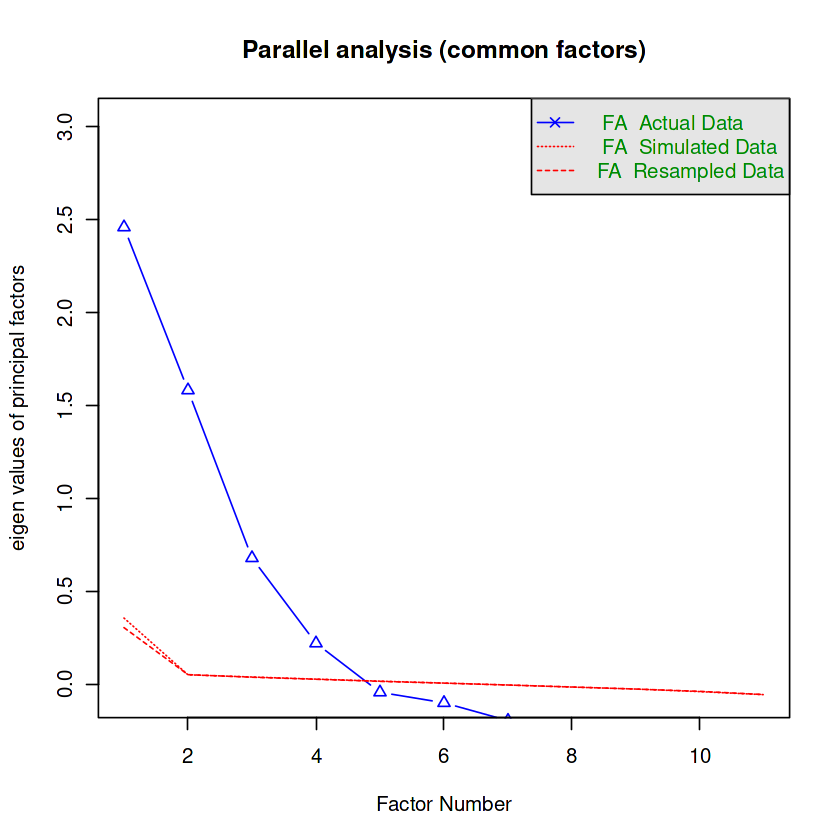

fit,RMSEA,BIC
<dbl>,<dbl>,<dbl>
0.4277753,0.3041352,26100.003
0.7228539,0.2567085,14292.528
0.8314436,0.2515807,10085.866
0.8058002,0.2802951,8545.219
0.8028718,0.3187577,6523.583
0.7404954,0.4019609,4167.833


[1] 0.07340989 0.07229461 0.07632566 0.09762940 0.11477252 0.16856488

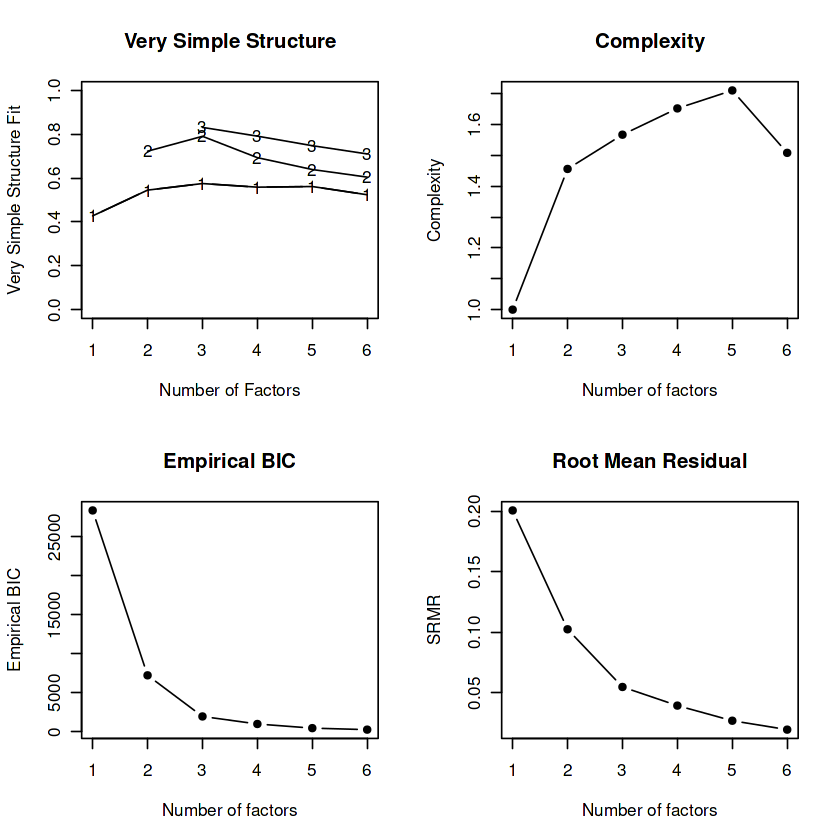

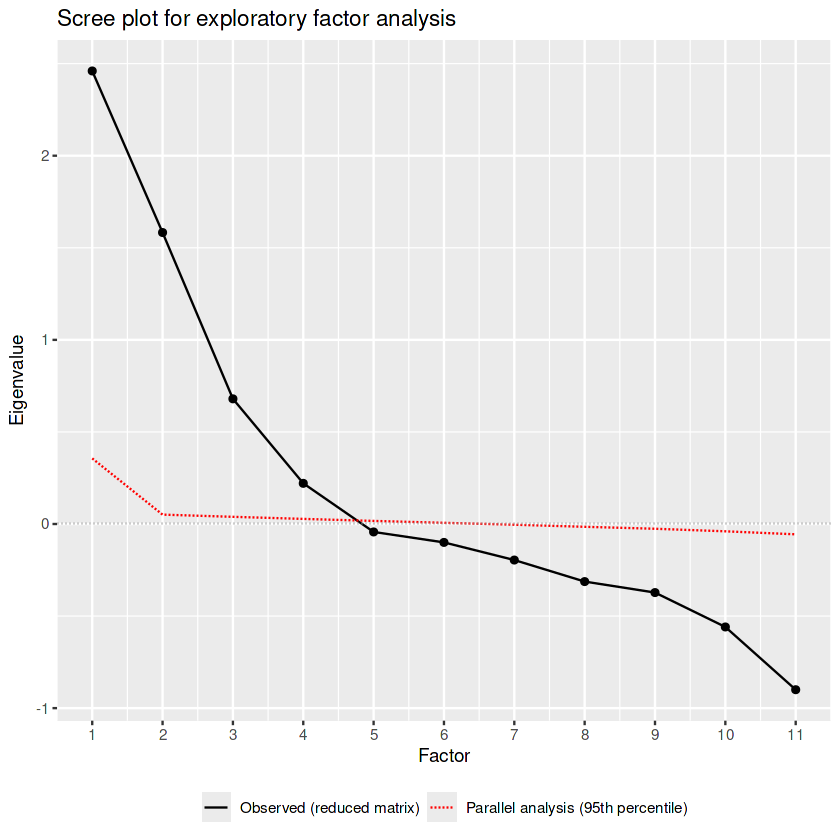

In [82]:
set.seed(123)
pa_efa <- fa.parallel(wine[vars11], fa = "fa", fm = "minres",
                      n.iter = 100, quant = .95,
                      main = "Parallel analysis (common factors)")
pa_efa$nfact                        
 
ev_full    <- eigen(R11)$values
ev_reduced <- pa_efa$fa.values
tibble(factor = 1:11,
       eig_full = ev_full,
       eig_reduced = ev_reduced,
       pa_threshold = pa_efa$fa.sim[1:11]) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))
 

nf <- nfactors(R11, n = 6, rotate = "oblimin", fm = "minres", n.obs = nrow(wine))
nf$vss.stats[, c("fit", "RMSEA", "BIC")]   
nf$map                                     
 
p_scree_efa <- tibble(idx = 1:11, observed = ev_reduced, pa = pa_efa$fa.sim[1:11]) %>%
  ggplot(aes(idx)) +
  geom_line(aes(y = observed, linetype = "Observed (reduced matrix)")) +
  geom_point(aes(y = observed)) +
  geom_line(aes(y = pa, linetype = "Parallel analysis (95th percentile)"), color = "red") +
  geom_hline(yintercept = 0, color = "grey60", linetype = "dotted") +
  scale_x_continuous(breaks = 1:11) +
  labs(title = "Scree plot for exploratory factor analysis",
       x = "Factor", y = "Eigenvalue", linetype = NULL) +
  theme(legend.position = "bottom")
p_scree_efa

### Fit the model: minimum residual extraction, oblimin rotation

In [83]:


nf_final <- 3   
efa <- fa(wine[vars11], nfactors = nf_final, rotate = "oblimin",
          fm = "minres", scores = "regression")

print(efa$loadings, cutoff = .30, digits = 2)  
round(efa$Phi, 2)                              

Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”



Loadings:
                     MR1   MR2   MR3  
fixed_acidity        -0.43        0.61
volatile_acidity     -0.55  0.34 -0.32
citric_acid                       0.69
residual_sugar        0.60  0.45      
chlorides            -0.39  0.39      
free_sulfur_dioxide   0.70            
total_sulfur_dioxide  0.86            
density                     1.01      
pH                               -0.47
sulphates            -0.40            
alcohol                    -0.66      

                MR1  MR2  MR3
SS loadings    2.55 2.07 1.19
Proportion Var 0.23 0.19 0.11
Cumulative Var 0.23 0.42 0.53


,MR1,MR2,MR3
MR1,1.00,-0.02,0.01
MR2,-0.02,1.00,0.17
MR3,0.01,0.17,1.00


### Comparison of solutions

In [84]:
fit_row <- function(m) {
  L <- unclass(m$loadings)
  tibble(n_factors   = m$factors,
         RMSR        = m$rms,
         RMSEA       = unname(m$RMSEA["RMSEA"]),
         TLI         = m$TLI,
         BIC         = m$BIC,
         prop_var    = mean(m$communality),
         n_weak      = sum(apply(abs(L), 1, max) < .40),
         n_crossload = sum(rowSums(abs(L) >= .30) > 1),
         heywood     = any(m$communality >= 1))
}

efa_set <- lapply((nf_final - 1):(nf_final + 1),
                  function(k) fa(wine[vars11], nfactors = k, rotate = "oblimin", fm = "minres"))

bind_rows(lapply(efa_set, fit_row)) %>% round_df(3)

Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”
Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”
Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate =

n_factors,RMSR,RMSEA,TLI,BIC,prop_var,n_weak,n_crossload,heywood
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
2,0.102,0.257,0.364,14292.528,0.423,3,3,TRUE
3,0.055,0.252,0.389,10085.866,0.531,2,4,TRUE
4,0.040,0.280,0.242,8545.219,0.582,1,4,TRUE


### Loadings, communalities, uniquenesses, cross-loadings

In [86]:
### Pattern matrix, communalities, uniquenesses

L <- unclass(efa$loadings)
fnames_raw <- colnames(L)

loadings_efa <- tibble(variable = vars11) %>%
  bind_cols(as_tibble(L)) %>%
  mutate(h2         = as.numeric(efa$communality),
         u2         = as.numeric(efa$uniquenesses),
         primary    = fnames_raw[max.col(abs(L))],
         max_load   = apply(abs(L), 1, max),
         n_salient  = rowSums(abs(L) >= .40),
         cross_load = rowSums(abs(L) >= .30) > 1,
         weak       = max_load < .40)

round_df(loadings_efa)

any(efa$communality >= 1)                # Heywood check (expect TRUE because of density)
round(efa$Vaccounted, 3)
round(unclass(efa$Structure), 2)

tibble(RMSR = efa$rms, RMSEA = unname(efa$RMSEA["RMSEA"]),
       RMSEA_low = unname(efa$RMSEA["lower"]), RMSEA_high = unname(efa$RMSEA["upper"]),
       TLI = efa$TLI, BIC = efa$BIC) %>% round_df(3)

variable,MR1,MR2,MR3,h2,u2,primary,max_load,n_salient,cross_load,weak
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>
fixed_acidity,-0.43,0.27,0.61,0.70,0.30,MR3,0.61,2,TRUE,FALSE
volatile_acidity,-0.55,0.34,-0.32,0.49,0.51,MR1,0.55,1,TRUE,FALSE
citric_acid,0.19,-0.06,0.69,0.51,0.49,MR3,0.69,1,FALSE,FALSE
residual_sugar,0.60,0.45,0.02,0.55,0.45,MR1,0.60,2,TRUE,FALSE
chlorides,-0.39,0.39,0.05,0.32,0.68,MR1,0.39,0,TRUE,TRUE
free_sulfur_dioxide,0.70,0.07,-0.02,0.49,0.51,MR1,0.70,1,FALSE,FALSE
total_sulfur_dioxide,0.86,0.08,0.01,0.74,0.26,MR1,0.86,1,FALSE,FALSE
density,0.00,1.01,0.04,1.04,-0.04,MR2,1.01,1,FALSE,FALSE
pH,-0.28,0.03,-0.47,0.29,0.71,MR3,0.47,1,FALSE,FALSE


[1] TRUE

,MR1,MR2,MR3
SS loadings,2.556,2.083,1.199
Proportion Var,0.232,0.189,0.109
Cumulative Var,0.232,0.422,0.531
Proportion Explained,0.438,0.357,0.205
Cumulative Proportion,0.438,0.795,1.000


,MR1,MR2,MR3
fixed_acidity,-0.44,0.39,0.66
volatile_acidity,-0.56,0.29,-0.26
citric_acid,0.19,0.05,0.68
residual_sugar,0.59,0.44,0.10
chlorides,-0.40,0.41,0.12
free_sulfur_dioxide,0.70,0.05,-0.01
total_sulfur_dioxide,0.86,0.07,0.03
density,-0.02,1.02,0.22
pH,-0.28,-0.04,-0.46
sulphates,-0.40,0.24,0.12


RMSR,RMSEA,RMSEA_low,RMSEA_high,TLI,BIC
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.055,0.252,0.248,0.256,0.389,10085.87


In [87]:
### Sensitivity: refit without density (Heywood case)

efa_nd <- fa(wine[vars_nodens], nfactors = nf_final, rotate = "oblimin",
             fm = "minres", scores = "regression")

print(efa_nd$loadings, cutoff = .30, digits = 2)
round(efa_nd$Phi, 2)
any(efa_nd$communality >= 1)             # should be FALSE
round(efa_nd$Vaccounted, 3)

# Congruence with the pooled solution on the 10 shared variables
L_shared <- unclass(efa$loadings)[vars_nodens, ]
round(abs(factor.congruence(L_shared, unclass(efa_nd$loadings))), 3)

tibble(RMSR = efa_nd$rms, RMSEA = unname(efa_nd$RMSEA["RMSEA"]),
       TLI = efa_nd$TLI, BIC = efa_nd$BIC) %>% round_df(3)


Loadings:
                     MR1   MR3   MR2  
fixed_acidity               0.32  0.60
volatile_acidity            0.51      
citric_acid                       0.71
residual_sugar        0.64            
chlorides                   0.64      
free_sulfur_dioxide   0.70            
total_sulfur_dioxide  0.87            
pH                               -0.47
sulphates                   0.33      
alcohol              -0.51 -0.54      

                MR1  MR3  MR2
SS loadings    2.23 1.23 1.19
Proportion Var 0.22 0.12 0.12
Cumulative Var 0.22 0.35 0.46


,MR1,MR3,MR2
MR1,1.00,-0.27,0.07
MR3,-0.27,1.00,0.09
MR2,0.07,0.09,1.00


[1] FALSE

,MR1,MR3,MR2
SS loadings,2.276,1.278,1.198
Proportion Var,0.228,0.128,0.120
Cumulative Var,0.228,0.355,0.475
Proportion Explained,0.479,0.269,0.252
Cumulative Proportion,0.479,0.748,1.000


,MR1,MR3,MR2
MR1,0.94,0.43,0.06
MR2,0.31,0.88,0.09
MR3,0.03,0.05,1.00


RMSR,RMSEA,TLI,BIC
<dbl>,<dbl>,<dbl>,<dbl>
0.048,0.139,0.704,2116.248


### Factor names and red vs. white scores

In [89]:
factor_names <- c("Preservation (SO2) vs. volatile acidity/salts",
                  "Body (density-extract) vs. alcohol",
                  "Fixed-acid strength")     # confirm against Chunk 3 output
stopifnot(length(factor_names) == nf_final)

fscores <- as_tibble(efa$scores)
names(fscores) <- factor_names
fscores$color <- wine$color

efa_score_by_color <- fscores %>%
  pivot_longer(-color, names_to = "factor", values_to = "score") %>%
  group_by(factor, color) %>%
  summarise(M = mean(score), SD = sd(score), .groups = "drop")
round_df(efa_score_by_color)

efa_score_d <- sapply(factor_names, function(f) {
  x <- fscores[[f]]; g <- fscores$color
  n1 <- sum(g == "red"); n2 <- sum(g == "white")
  sp <- sqrt(((n1 - 1) * var(x[g == "red"]) + (n2 - 1) * var(x[g == "white"])) / (n1 + n2 - 2))
  (mean(x[g == "red"]) - mean(x[g == "white"])) / sp
})
round(efa_score_d, 2)  

factor,color,M,SD
<chr>,<chr>,<dbl>,<dbl>
Body (density-extract) vs. alcohol,red,0.87,0.92
Body (density-extract) vs. alcohol,white,-0.28,1.14
Fixed-acid strength,red,-0.03,1.36
Fixed-acid strength,white,0.01,0.63
Preservation (SO2) vs. volatile acidity/salts,red,-1.32,0.46
Preservation (SO2) vs. volatile acidity/salts,white,0.43,0.58


Preservation (SO2) vs. volatile acidity/salts 
                                        -3.17 
           Body (density-extract) vs. alcohol 
                                         1.06 
                          Fixed-acid strength 
                                        -0.04

### Visualizations

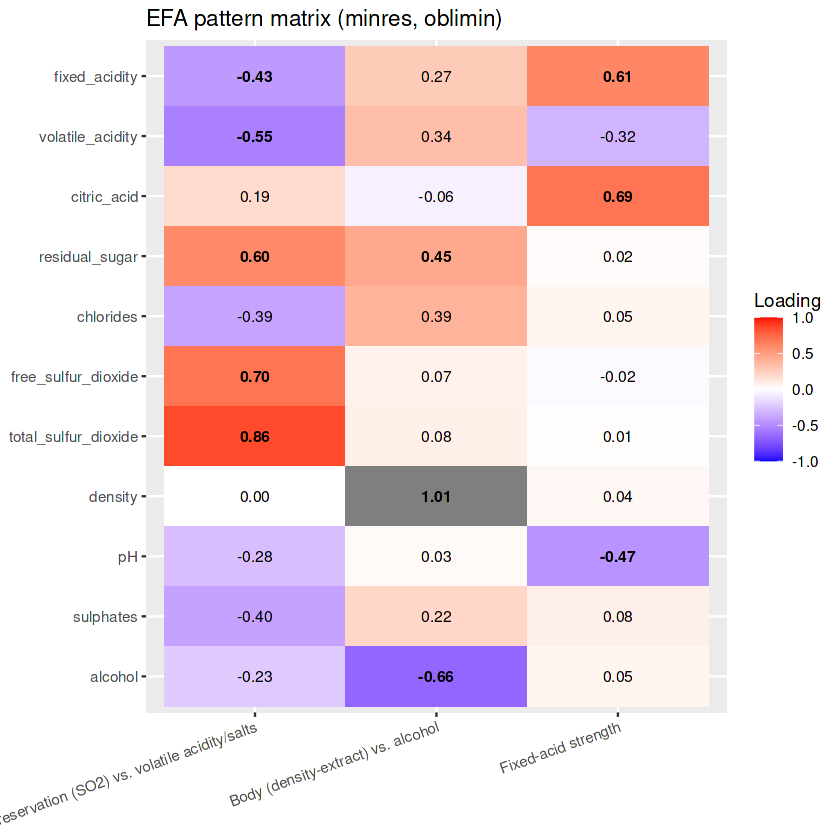

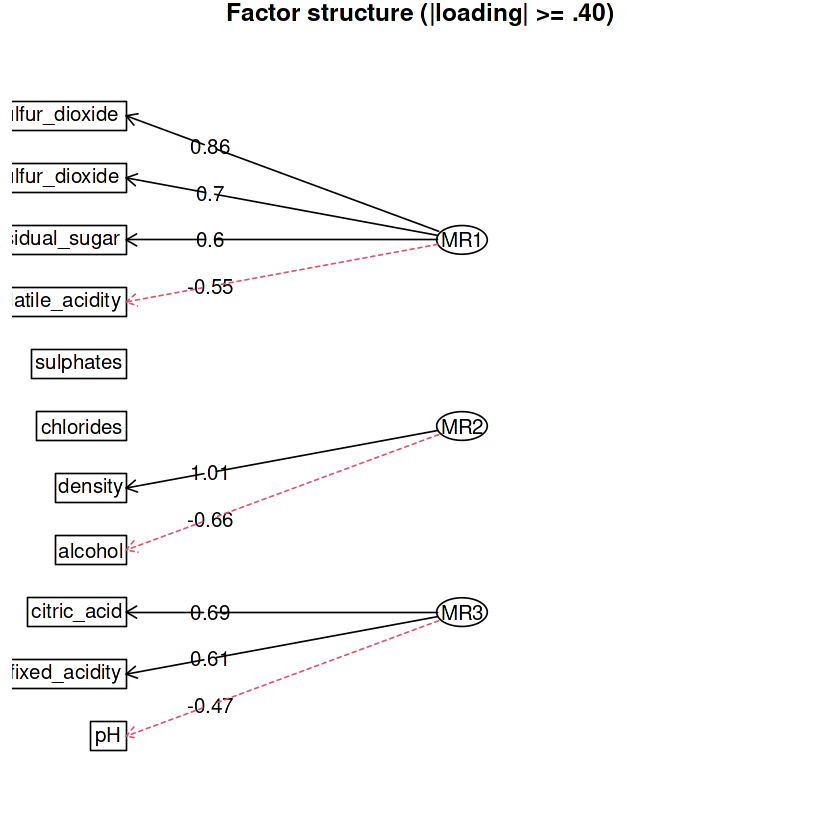

In [90]:
p_efa_load <- loadings_efa %>%
  select(variable, all_of(fnames_raw)) %>%
  pivot_longer(-variable, names_to = "factor", values_to = "loading") %>%
  mutate(factor   = factor(factor, levels = fnames_raw, labels = factor_names),
         variable = factor(variable, levels = rev(vars11))) %>%
  ggplot(aes(factor, variable, fill = loading)) +
  geom_tile() +
  geom_text(aes(label = sprintf("%.2f", loading),
                fontface = ifelse(abs(loading) >= .40, "bold", "plain")), size = 3.2) +
  scale_fill_gradient2(low = "blue", mid = "white", high = "red", limits = c(-1, 1)) +
  labs(title = "EFA pattern matrix (minres, oblimin)", x = NULL, y = NULL, fill = "Loading") +
  theme(axis.text.x = element_text(angle = 20, hjust = 1))
p_efa_load

fa.diagram(efa, cut = .40, digits = 2, main = "Factor structure (|loading| >= .40)")

### Robustness Check

In [91]:
keep <- md_all <= cut_all

efa_promax <- fa(wine[vars11], nfactors = nf_final, rotate = "promax",  fm = "minres")
efa_ml     <- fa(wine[vars11], nfactors = nf_final, rotate = "oblimin", fm = "ml")
efa_out    <- fa(wine[keep, vars11], nfactors = nf_final, rotate = "oblimin", fm = "minres")
efa_red    <- fa(wine[wine$color == "red",   vars11], nfactors = nf_final, rotate = "oblimin", fm = "minres")
efa_white  <- fa(wine[wine$color == "white", vars11], nfactors = nf_final, rotate = "oblimin", fm = "minres")

tucker_match <- function(ref, alt, label) {
  cg <- abs(factor.congruence(unclass(ref$loadings), unclass(alt$loadings)))
  tibble(comparison    = label,
         pooled_factor = factor_names,
         matched_to    = colnames(cg)[apply(cg, 1, which.max)],
         congruence    = apply(cg, 1, max))
}

robust_tbl <- bind_rows(
  tucker_match(efa, efa_promax, "Promax rotation"),
  tucker_match(efa, efa_ml,     "Maximum likelihood"),
  tucker_match(efa, efa_out,    "Without multivariate outliers"),
  tucker_match(efa, efa_red,    "Red wines only"),
  tucker_match(efa, efa_white,  "White wines only"))
round_df(robust_tbl, 3)    # >= .95 = essentially identical

print(efa_red$loadings,   cutoff = .30, digits = 2)
print(efa_white$loadings, cutoff = .30, digits = 2)
any(efa_red$communality >= 1); any(efa_white$communality >= 1)

Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”
Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”
Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate =

comparison,pooled_factor,matched_to,congruence
<chr>,<chr>,<chr>,<dbl>
Promax rotation,Preservation (SO2) vs. volatile acidity/salts,MR1,0.88
Promax rotation,Body (density-extract) vs. alcohol,MR2,0.93
Promax rotation,Fixed-acid strength,MR3,0.98
Maximum likelihood,Preservation (SO2) vs. volatile acidity/salts,ML3,0.94
Maximum likelihood,Body (density-extract) vs. alcohol,ML2,0.97
Maximum likelihood,Fixed-acid strength,ML1,0.88
Without multivariate outliers,Preservation (SO2) vs. volatile acidity/salts,MR1,0.99
Without multivariate outliers,Body (density-extract) vs. alcohol,MR2,1.00
Without multivariate outliers,Fixed-acid strength,MR3,0.98



Loadings:
                     MR1   MR3   MR2  
fixed_acidity         0.59  0.46      
volatile_acidity     -0.66  0.31      
citric_acid           0.92            
residual_sugar                        
chlorides                             
free_sulfur_dioxide               0.78
total_sulfur_dioxide              0.86
density                     0.87      
pH                   -0.50 -0.34      
sulphates             0.38            
alcohol               0.30 -0.63      

                MR1  MR3  MR2
SS loadings    2.16 1.67 1.46
Proportion Var 0.20 0.15 0.13
Cumulative Var 0.20 0.35 0.48

Loadings:
                     MR1   MR3   MR2  
fixed_acidity                     0.82
volatile_acidity                      
citric_acid                       0.36
residual_sugar        0.74            
chlorides                             
free_sulfur_dioxide         0.74      
total_sulfur_dioxide        0.84      
density               1.04            
pH                               -0.50

[1] FALSE

[1] TRUE

### Export

In [ ]:

#dir.create("output/figures", recursive = TRUE, showWarnings = FALSE)
#dir.create("output/tables",  recursive = TRUE, showWarnings = FALSE)

#write_csv(tibble(variable = vars11, MSA = as.numeric(kmo_efa$MSAi)), "output/tables/efa_kmo_by_variable.csv")
#write_csv(tibble(kmo_overall = as.numeric(kmo_efa$MSA), bartlett_chisq = bart_efa$chisq,
#                 df = bart_efa$df, p = bart_efa$p.value, det_R = det(R11)),
#          "output/tables/efa_kmo_bartlett.csv")
#write_csv(bind_rows(lapply(efa_set, fit_row)), "output/tables/efa_solution_comparison.csv")
#write_csv(loadings_efa, "output/tables/efa_loadings_communalities.csv")
#write.csv(round(efa$Phi, 3), "output/tables/efa_factor_correlations.csv")
#write.csv(round(unclass(efa_nd$loadings), 3), "output/tables/efa_loadings_no_density.csv")
#write_csv(efa_score_by_color, "output/tables/efa_scores_by_color.csv")
#write_csv(tibble(factor = names(efa_score_d), cohens_d_red_minus_white = as.numeric(efa_score_d)),
#          "output/tables/efa_scores_cohens_d.csv")
#write_csv(robust_tbl, "output/tables/efa_robustness_congruence.csv")

#ggsave("output/figures/efa_scree_parallel.png", plot = p_scree_efa, width = 7, height = 4.5, dpi = 300)
#ggsave("output/figures/efa_loading_heatmap.png", plot = p_efa_load, width = 8, height = 6, dpi = 300)
#png("output/figures/efa_diagram.png", width = 2000, height = 1600, res = 300)
#fa.diagram(efa, cut = .40, digits = 2, main = "Factor structure (|loading| >= .40)")
#dev.off()

In [92]:

dir.create("output/figures", recursive = TRUE, showWarnings = FALSE)
dir.create("output/tables",  recursive = TRUE, showWarnings = FALSE)

write_csv(tibble(variable = vars11, MSA = as.numeric(kmo_efa$MSAi)), "output/tables/efa_kmo_by_variable.csv")
write_csv(tibble(kmo_overall = as.numeric(kmo_efa$MSA), bartlett_chisq = bart_efa$chisq,
                 df = bart_efa$df, p = bart_efa$p.value, det_R = det(R11)),
          "output/tables/efa_kmo_bartlett.csv")
write_csv(bind_rows(lapply(efa_set, fit_row)), "output/tables/efa_solution_comparison.csv")
write_csv(loadings_efa, "output/tables/efa_loadings_communalities.csv")
write.csv(round(efa$Phi, 3), "output/tables/efa_factor_correlations.csv")
write.csv(round(unclass(efa_nd$loadings), 3), "output/tables/efa_loadings_no_density.csv")
write_csv(efa_score_by_color, "output/tables/efa_scores_by_color.csv")
write_csv(tibble(factor = names(efa_score_d), cohens_d_red_minus_white = as.numeric(efa_score_d)),
             "output/tables/efa_scores_cohens_d.csv")
write_csv(robust_tbl, "output/tables/efa_robustness_congruence.csv")

ggsave("output/figures/efa_scree_parallel.png", plot = p_scree_efa, width = 7, height = 4.5, dpi = 300)
ggsave("output/figures/efa_loading_heatmap.png", plot = p_efa_load, width = 8, height = 6, dpi = 300)
png("output/figures/efa_diagram.png", width = 2000, height = 1600, res = 300)
fa.diagram(efa, cut = .40, digits = 2, main = "Factor structure (|loading| >= .40)")
dev.off()

pdf 
  2